# **Telco Customer Churn**

**Created by Annisa Andez Aunillah**

## **Business Problem Understanding**

**Context**<br>

Industri telekomunikasi yang makin beragam menyebabkan persaingan yang lebih ketat. Pelanggan mudah berpindah ke operator lain. Biaya mendapatkan pelanggan baru umumnya lebih besar daripada biaya mempertahankan pelanggan yang sudah ada (loyal customer). Maka dari itu, pelanggan yang berhenti berlangganan (*customer churn*) berdampak langsung pada pendapatan perusahaan telekomunikasi.<br>
Perusahaan memiliki data pelanggan yang berhenti berlangganan (*customer churn*) atau pelanggan yang lanjut berlangganan (*customer not churn*). Data pelanggan ini memungkinkan digunakan untuk mengenali pola pelanggan yang berhenti berlangganan, sehingga perusahaan dapat melakukan upaya retensi pada pelanggan tersebut.<br>
<br>
**Target**:<br>
0 : Customer Not Churn<br>
1 : Customer Churn

**Problem Statement:**<br>
<br>
Perusahaan belum memiliki cara untuk mengetahui pelanggan mana yang akan berhenti berlangganan. Dalam proses mempertahankan pelanggan agar tidak berhenti berlangganan, perusahaan harus mengeluarkan biaya untuk memberikan promo atau penawaran khusus. Di sisi lain, proses mendapatkan pelanggan baru jauh lebih sulit.

**Goals:**<br>
<br>
Maka berdasarkan permasalahan tersebut, perusahaan ingin memiliki kemampuan untuk memprediksi kemungkinan pelangganan akan berhenti berlangganan atau tidak, sehingga dapat memfokuskan upaya retensi pada pelanggan yang kemungkinan akan berhenti. Dan juga, perusahaan ingin mengetahui apa/faktor/variabel apa yang membuat pelangganan akan berhenti berlangganan atau tidak, sehingga mereka dapat membuat rencana yang lebih baik dalam melakukan upaya terbaik terhadap pelanggan yang kemungkinan akan berhenti berlangganan.<br>
<br>
**Analytic Approach:**<br>
<br>
Jadi yang akan kita lakukan adalah menganalisis data untuk menemukan pola yang membedakan pelangganan akan berhenti berlangganan atau tidak. Kemudian kita akan membangun model klasifikasi yang akan membantu perusahaan untuk dapat memprediksi probabilitas pelangganan akan berhenti berlangganan atau tidak.

**Metric Evaluation:**<br>

| Tipe Error | Detail |
| --- | ---|
| False Positive | Model memprediksi pelanggan yang tidak churn sebagai pelanggan yang churn |
| False Negative | Model memprediksi pelanggan yang churn sebagai pelanggan yang tidak churn |

<br>
Dari tabel diatas, konsekuensi dari False Positive adalah perusahaan harus mengeluarkan biaya untuk memberikan promo atau penawaran khusus agar pelanggan yang diprediksi churn akan tetap berlangganan. Konsekuensi dari False Negative adalah perusahaan tidak melakukan retensi kepada pelanggan yang churn sehingga pelanggan pindah ke operator lain. Konsekuensi tersebut menyebabkan pelanggan kehilangan pelanggan dan biaya mendapatkan pelanggan baru lebih mahal.<br>
<br>

False Positive : Kita asumsikan cost untuk upaya retensi pelangganan akan tetap berlangganan adalah Rp 100,000<br>
False Negative : Kita asumsikan cost untuk kehilangan pelanggan dan biaya akuisisi pelanggan baru adalah Rp 500,000<br>
Kita asumsikan cost False Positive dan False Negaative diatas dengan menggunakan ratio **FP:FN = 1:5**<br>
<br>
Dari penjelasan konsekuensi False Positive dan False Negative diatas, matriks yang cocok untuk adalah F2 karena cost FN lebih mahal daripada cost FP. Matriks F2 dapat menekan recall (menekan cost FN), namun dapat menekan precision (menekan FP) jika FP berlebihan.

## **Data Understanding**

**Context**<br>
<br>
Dataset mempresentasikan profil pelanggan yang telah meninggalkan perusahaan telekomunikasi. Istilah **Churn** dalam telekomunikasi dan layanan berbasis langganan lainnya merupakan situasi ketike pelanggan meninggalkan profider layanan tersebut.

**Features**
| Column | Description |
| --- | --- |
| Dependents | Status pelanggan memiliki tanggungan atau tidak |
| Tenure | Jumlah bulan pelanggan sudah berlanggangan dengan perusahaan telekomunikasi |
| OnlineSecurity | Status pelanggan memiliki Online Security atau tidak |
| OnlineBackup | Status pelanggan memiliki Online Backup atau tidak |
| InternetService | Status pelanggan berlangganan layanan internet atau tidak |
| DeviceProtection | Status pelanggan memiliki perlindungan perangkat atau tidak |
| TechSupport| Status pelanggan memiliki dukungan teknis atau tidak |
| Contract | Jenis kontrak berdasarkan durasi |
| PaperlessBilling | Tagihan dalam bentuk tanpa kertas (Yes/No) |
| MonthlyCharges| Total biaya untuk layanan secara bulanan |
| Churn | Status pelanggan **Churn** atau **Not Churn** |


# **Import Libary**

In [26]:
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import scipy.stats as stats
from scipy.stats import kstest

# Feature Engineering
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, OrdinalEncoder
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer
import category_encoders as ce

# Model Selection
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV, StratifiedKFold,train_test_split, cross_val_score, cross_validate, RepeatedStratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier

# modeling -> ensemble various type
from sklearn.ensemble import VotingClassifier, StackingClassifier

# ensemble similar type
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, AdaBoostRegressor

from xgboost import XGBClassifier
# metrics
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, make_scorer, fbeta_score
from sklearn.metrics import roc_curve, roc_auc_score, RocCurveDisplay
from sklearn.metrics import classification_report, average_precision_score

# pipeline
from sklearn.pipeline import Pipeline

# imbalanced 
from imblearn.under_sampling import RandomUnderSampler, CondensedNearestNeighbour, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline

# Ignore Warning
import sys
import warnings
if not sys.warnoptions:
    warnings.simplefilter("ignore")

# Set max columns
pd.set_option('display.max_columns', None)

# **Load Dataset**

In [27]:
df = pd.read_csv('data_telco_customer_churn.csv')
df

,Dependents,tenure,OnlineSecurity,OnlineBackup,InternetService,DeviceProtection,TechSupport,Contract,PaperlessBilling,MonthlyCharges,Churn
0,Yes,9,No,No,DSL,Yes,Yes,Month-to-month,Yes,72.90,Yes
1,No,14,No,Yes,Fiber optic,Yes,No,Month-to-month,Yes,82.65,No
2,No,64,Yes,No,DSL,Yes,Yes,Two year,No,47.85,Yes
3,No,72,Yes,Yes,DSL,Yes,Yes,Two year,No,69.65,No
4,No,3,No internet service,No internet service,No,No internet service,No internet service,Month-to-month,Yes,23.60,No
...,...,...,...,...,...,...,...,...,...,...,...
4925,No,15,No,No,Fiber optic,Yes,Yes,Month-to-month,Yes,103.45,No
4926,Yes,10,No,No,Fiber optic,Yes,Yes,Month-to-month,Yes,91.10,No
4927,No,58,No internet service,No internet service,No,No internet service,No internet service,Two year,No,20.75,No
4928,No,1,No,No,Fiber optic,No,No,Month-to-month,Yes,69.75,Yes


In [28]:
# Cek jumlah dan tipe data tiap kolom
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4930 entries, 0 to 4929
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Dependents        4930 non-null   str    
 1   tenure            4930 non-null   int64  
 2   OnlineSecurity    4930 non-null   str    
 3   OnlineBackup      4930 non-null   str    
 4   InternetService   4930 non-null   str    
 5   DeviceProtection  4930 non-null   str    
 6   TechSupport       4930 non-null   str    
 7   Contract          4930 non-null   str    
 8   PaperlessBilling  4930 non-null   str    
 9   MonthlyCharges    4930 non-null   float64
 10  Churn             4930 non-null   str    
dtypes: float64(1), int64(1), str(9)
memory usage: 657.6 KB


In [29]:
# Menampilkan tabel keterangan tiap kolom pada dataset churn
df_col_unique=pd.DataFrame({
    'feature_name':df.columns,
    'dataType':[df[col].dtype for col in df.columns],
    'uniqueValue':[df[col].unique().tolist() for col in df.columns],
    'uniqueCount':[df[col].nunique() for col in df.columns],
    'missingValue':['Yes' if df[col].isna().any() else 'No' for col in df.columns]
})
pd.set_option('display.max_colwidth', None)
df_col_unique

,feature_name,dataType,uniqueValue,uniqueCount,missingValue
0,Dependents,str,"[Yes, No]",2,No
1,tenure,int64,"[9, 14, 64, 72, 3, 40, 17, 11, 8, 47, 18, 5, 1, 48, 13, 58, 7, 4, 70, 34, 31, 37, 15, 71, 10, 43, 22, 33, 69, 54, 63, 55, 66, 56, 32, 26, 24, 2, 51, 23, 49, 28, 36, 45, 42, 6, 61, 59, 67, 65, 0, 16, 52, 41, 25, 62, 20, 50, 30, 60, 19, 35, 57, 27, 44, 53, 12, 46, 39, 29, 38, 68, 21]",73,No
2,OnlineSecurity,str,"[No, Yes, No internet service]",3,No
3,OnlineBackup,str,"[No, Yes, No internet service]",3,No
4,InternetService,str,"[DSL, Fiber optic, No]",3,No
5,DeviceProtection,str,"[Yes, No internet service, No]",3,No
6,TechSupport,str,"[Yes, No, No internet service]",3,No
7,Contract,str,"[Month-to-month, Two year, One year]",3,No
8,PaperlessBilling,str,"[Yes, No]",2,No
9,MonthlyCharges,float64,"[72.9, 82.65, 47.85, 69.65, 23.6, 74.55, 19.7, 44.05, 73.5, 40.3, 33.6, 96.25, 70.45, 30.55, 44.8, 20.0, 81.5, 94.35, 35.3, 50.7, 106.05, 56.3, 20.65, 98.9, 40.2, 81.2, 19.45, 116.1, 55.2, 94.45, 84.85, 19.6, 79.0, 74.7, 30.4, 55.8, 104.5, 70.55, 55.25, 96.65, 88.85, 109.25, 104.75, 74.4, 79.4, 74.1, 73.05, 94.6, 70.35, 79.6, 79.5, 90.7, 81.0, 87.75, 118.65, 24.8, 105.25, 57.8, 19.0, 25.7, 54.2, 44.85, 19.95, 81.05, 20.35, 85.25, 67.45, 100.3, 20.95, 105.2, 26.35, 82.15, 102.6, 106.15, 23.95, 115.8, 66.85, 90.35, 89.85, 73.35, 104.45, 35.45, 88.4, 70.5, 25.1, 39.0, 83.25, 74.3, 54.3, 50.45, 86.0, 19.55, 103.5, 91.7, 64.85, 99.65, 68.75, 106.25, 75.9, 94.4, ...]",1422,No


Hasil pengecekan dan tabel diatas menunjukkan bahwa tidak ada data yang hilang/kosong di semua kolom pada dataset. Dari kolom `uniqueValue` diatas juga tidak ada data yang duplikat (value berbeda namun artinya sama).

# **Data Cleaning & EDA**

Pada bagain ini dilakukan Exploratory Data Analysis (EDA) yang bertujuan sbb:
1. Melihat distribusi data tiap kolom
2. Mengetahui korelasi antarkolom
3. Mengetahui persebaran data churn dan tidak churn (target) berdasarkan feature yang ada

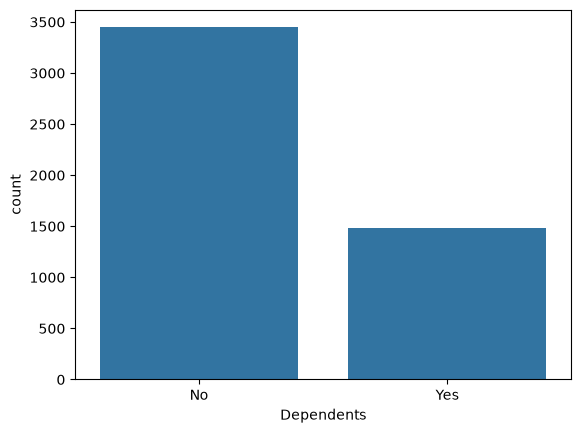

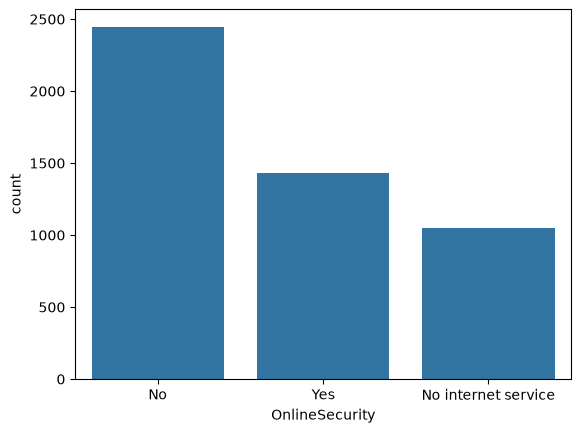

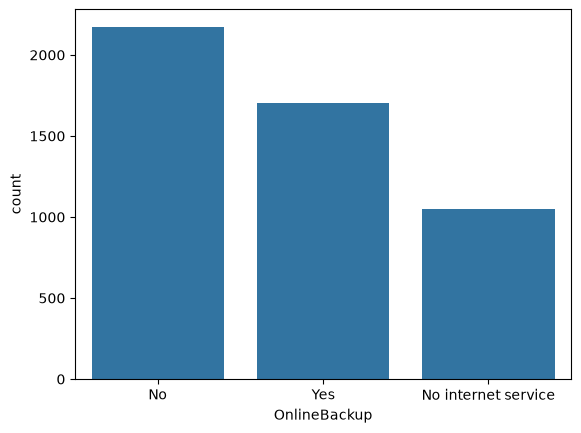

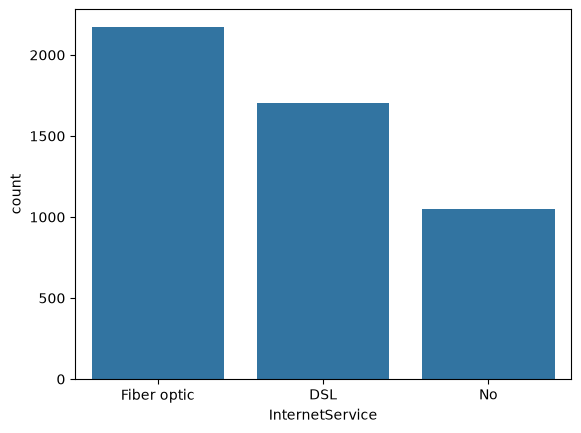

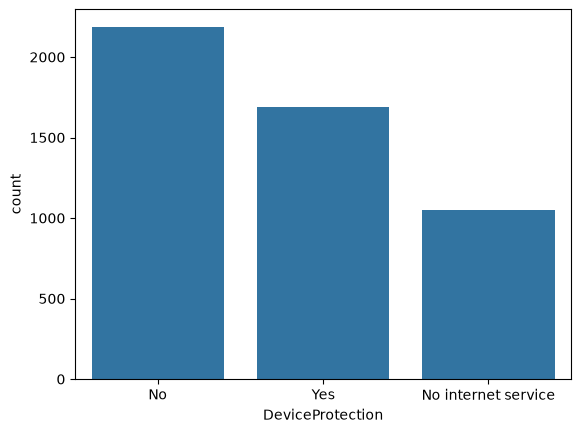

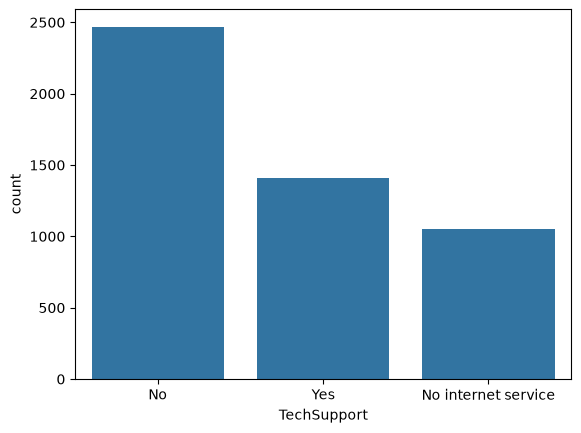

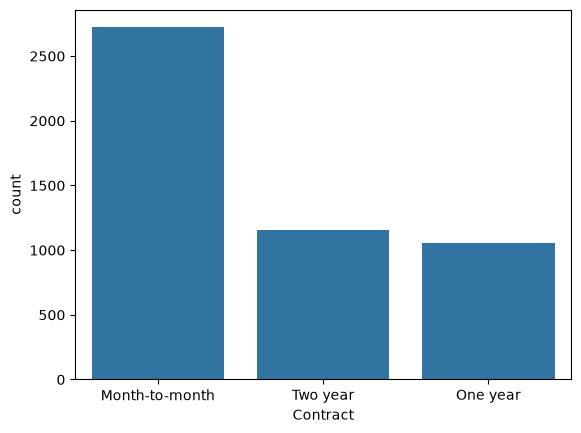

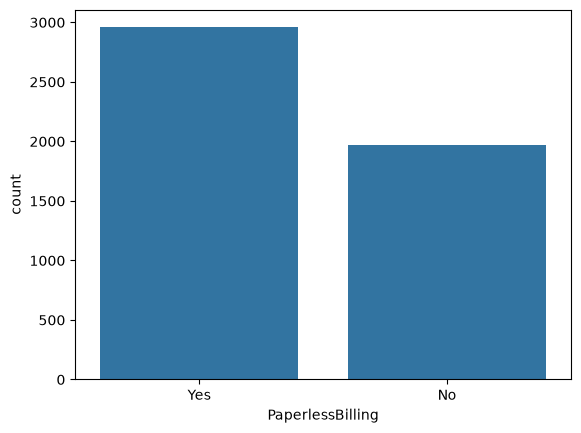

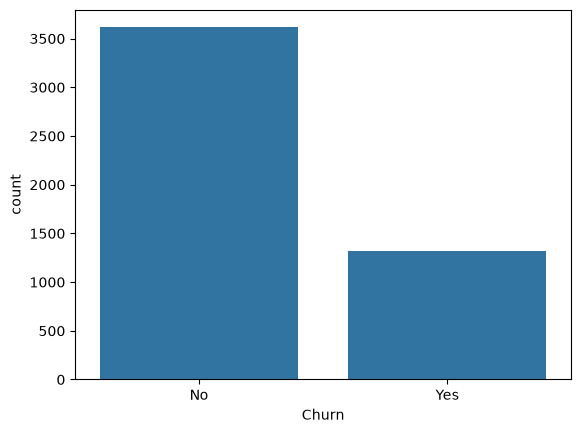

In [30]:
# Distribusi data tiap kolom kategorikal
cat_columns = df.select_dtypes(exclude='number').columns

for col in cat_columns:
    sns.countplot(data=df, x=col, order=df[col].value_counts().index)
    plt.show()

In [31]:
df.describe(include=['O'])

,Dependents,OnlineSecurity,OnlineBackup,InternetService,DeviceProtection,TechSupport,Contract,PaperlessBilling,Churn
count,4930,4930,4930,4930,4930,4930,4930,4930,4930
unique,2,3,3,3,3,3,3,2,2
top,No,No,No,Fiber optic,No,No,Month-to-month,Yes,No
freq,3446,2445,2172,2172,2186,2467,2721,2957,3614


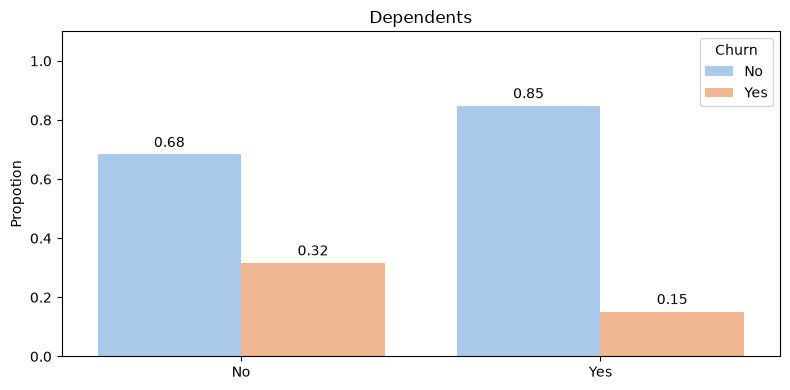

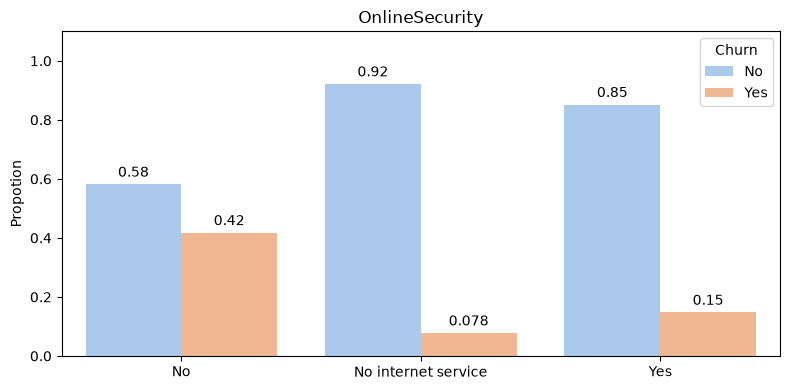

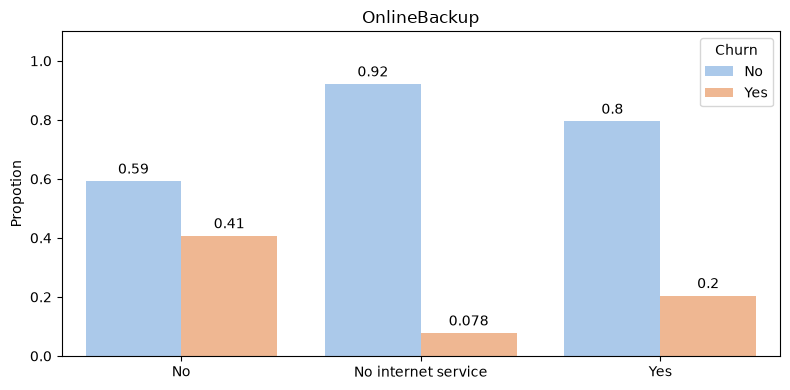

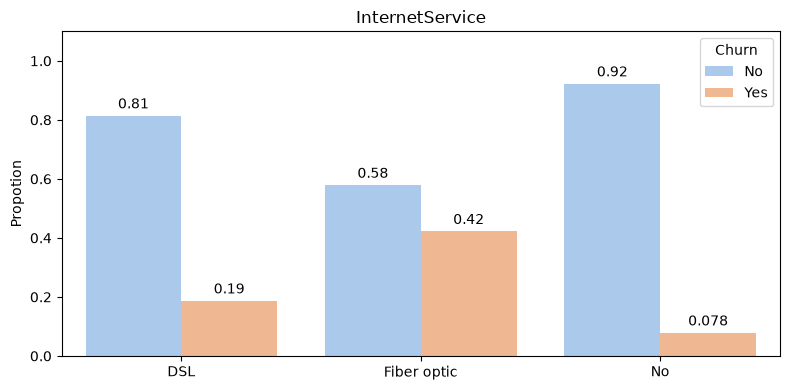

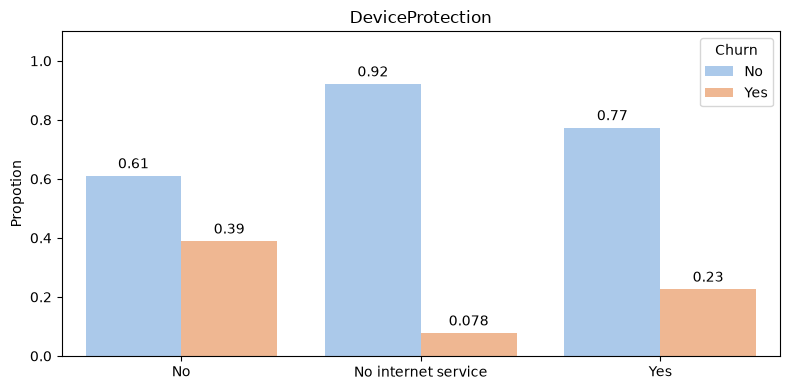

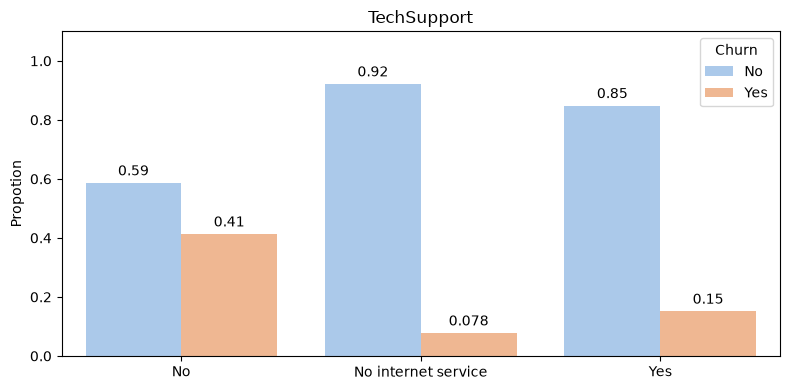

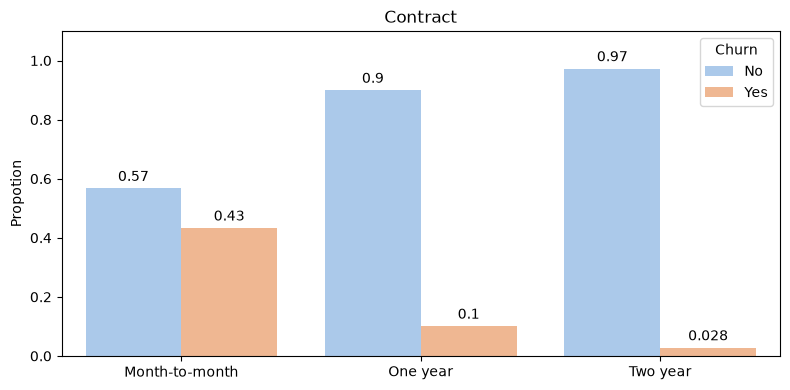

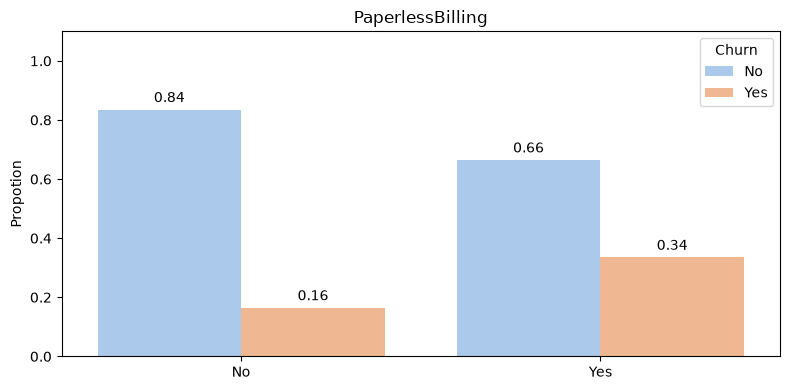

In [32]:
# Proporsi data tiap kolom kategorikal berdasarkan kolom Churn

cat_columns = [c for c in df.select_dtypes(exclude='number').columns
               if c != 'Churn']

for col in cat_columns:
    proportion = (df.groupby(col, observed=True)['Churn']
              .value_counts(normalize=True)
              .rename('Propotion')
              .reset_index())

    plt.figure(figsize=(8, 4))

    ax=sns.barplot(data=proportion, x=col, y='Propotion', hue='Churn',palette='pastel')

    for container in ax.containers:
        label = [f'{v:.2}' if pd.notna(v)else ''
                  for v in container.datavalues]
        ax.bar_label(container, labels=label, padding=3, fontsize=10)

    plt.title(col)
    plt.xlabel('')
    plt.ylim(0, 1.1)
    plt.tight_layout()
    plt.show()

Tabel diatas menunjukan proporsi data churn dan tidak churn pada tiap kolom kategorikal pada dataset. Kolom kategorikal dataset yaitu `Dependents`, `OnlineSecurity`, `OnlineBackup`, `InternetService`, `DeviceProtection`, `TechSupport`, `Contract`, dan `PaperlessBilling`.<br>
- Pada barplot data churn dan tidak churn pada kolom `Dependents`, proporsi pelanggan yang tidak churn lebih besar daripada pelanggan yang churn untuk semua pelanggan yang memiliki tanggungan maupun tidak (Yes dan No).
- Pada barplot data churn dan tidak churn pada kolom `OnlineSecurity`, proporsi pelanggan yang tidak churn lebih besar daripada pelanggan yang churn untuk semua pelanggan yang memiliki Online Security atau tidak. Pada kolom ini, terdapat 3 kelompok yaitu `No`, `No Internet Service`, dan `Yes`.
- Pada barplot data churn dan tidak churn pada kolom `OnlineBackup`, proporsi pelanggan yang tidak churn lebih besar daripada pelanggan yang churn untuk semua pelanggan yang memiliki Online Backup atau tidak. Pada kolom ini, terdapat 3 kelompok yaitu `No`, `No Internet Service`, dan `Yes`.
- Pada barplot data churn dan tidak churn pada kolom `InternetService`, proporsi pelanggan yang tidak churn lebih besar daripada pelanggan yang churn untuk semua pelanggan berlangganan layanan internet atau tidak. Pada kolom ini, terdapat 3 kelompok berdasarkan teknologi yang digunakan untuk menhantarkan koneksi internet yaitu `DSL`, `Fiber Optic`, dan `No`.
- Pada barplot data churn dan tidak churn pada kolom `DeviceProtection`, proporsi pelanggan yang tidak churn lebih besar daripada pelanggan yang churn untuk semua pelanggan yang memiliki perlindungan perangkat atau tidak. Pada kolom ini, terdapat 3 kelompok yaitu `No`, `No Internet Service`, dan `Yes`.
- Pada barplot data churn dan tidak churn pada kolom `TechSupport`, proporsi pelanggan yang tidak churn lebih besar daripada pelanggan yang churn untuk semua pelanggan yang memiliki dukungan teknis atau tidak. Pada kolom ini, terdapat 3 kelompok yaitu `No`, `No Internet Service`, dan `Yes`.
- Pada barplot data churn dan tidak churn pada kolom `Contract`, proporsi pelanggan yang tidak churn lebih besar daripada pelanggan yang churn untuk semua pelanggan berdasarkan tipe kontrak. Pada kolom ini, terdapat 3 kelompok yaitu `Month-to-month`, `One year`, dan `Two year`.
- Pada barplot data churn dan tidak churn pada kolom `PaperlessBilling`, proporsi pelanggan yang tidak churn lebih besar daripada pelanggan yang churn untuk semua tagihan pelanggan dalam bentuk tanpa kertas atau tidak (Yes dan No).

Pada barplot kolom `OnlineSecurity`, `OnlineBackup`,`DeviceProtection`, dan `TechSupport`, semua data churn dan tidak churn pada kelompok `No Internet Service` memiliki proporsi yang sama dengan barplot kolom `InternetService` pada kelompok `No Internet Service`. Proporsi data pelanggan yang tidak churn sebesar 0.97, sedangkan proporsi data pelanggan yang churn sebesar 0.028.<br>
Selanjutnya, akan dilakukan pengecekan apakah masing-masing kolom `OnlineSecurity`, `OnlineBackup`,`DeviceProtection`, dan `TechSupport` memiliki korelasi dengan kolom `InternetService`.

Pertama, kita akan cek proporsi distribusi data dari masing-masing kolom `OnlineSecurity`, `OnlineBackup`,`DeviceProtection`, dan `TechSupport` dengan `InternetService. Proporsi juga dipisah berdasarkan data churn dan tidak churn.

In [33]:
df_pivot_1 = pd.crosstab([df['InternetService'], df['OnlineSecurity']],
             df['Churn'], normalize='index')
df_pivot_1 = df_pivot_1.mul(100).round(2).map(lambda v: f'{v:.2f}%').transpose()

df_pivot_1

InternetService     DSL         Fiber optic                          No
OnlineSecurity       No     Yes          No     Yes No internet service
Churn                                                                  
No               72.57%  90.38%      50.35%  77.83%              92.21%
Yes              27.43%   9.62%      49.65%  22.17%               7.79%

In [34]:
df_pivot_2 = pd.crosstab([df['InternetService'], df['OnlineBackup']],
             df['Churn'], normalize='index')
df_pivot_2 = df_pivot_2.mul(100).round(2).map(lambda v: f'{v:.2f}%').transpose()

df_pivot_2

InternetService     DSL         Fiber optic                          No
OnlineBackup         No     Yes          No     Yes No internet service
Churn                                                                  
No               74.19%  89.95%      48.07%  70.86%              92.21%
Yes              25.81%  10.05%      51.93%  29.14%               7.79%

In [35]:
df_pivot_3 = pd.crosstab([df['InternetService'], df['DeviceProtection']],
             df['Churn'], normalize='index')
df_pivot_3 = df_pivot_3.mul(100).round(2).map(lambda v: f'{v:.2f}%').transpose()

df_pivot_3

InternetService      DSL         Fiber optic                          No
DeviceProtection      No     Yes          No     Yes No internet service
Churn                                                                   
No                75.18%  89.21%      50.12%  67.91%              92.21%
Yes               24.82%  10.79%      49.88%  32.09%               7.79%

In [37]:
df_pivot_4 = pd.crosstab([df['InternetService'], df['TechSupport']],
             df['Churn'], normalize='index')
df_pivot_4 = df_pivot_4.mul(100).round(2).map(lambda v: f'{v:.2f}%').transpose()

df_pivot_4

InternetService     DSL         Fiber optic                          No
TechSupport          No     Yes          No     Yes No internet service
Churn                                                                  
No               73.05%  90.28%      50.63%  77.21%              92.21%
Yes              26.95%   9.72%      49.37%  22.79%               7.79%

4 pivot table diatas menunjukkan bahwa proporsi data dari masing-masing kolom `OnlineSecurity`, `OnlineBackup`,`DeviceProtection`, dan `TechSupport` untuk kelompok `No Internet Service` dengan `InternetService` untuk kelompok `No` memiliki proporsi yang sama. Pada kelompok tersebut, proporsi pelanggan yang tidak churn adalah 92.21%, sedangkan proporsi pelanggan yang churn adalah 7.79%.

Kedua, kita akan lakukan uji statistik untuk menguji apakah ada hubungan pada masing-masing kolom (variabel).<br>
Akan dilakukan Chi Squared ($𝜒^2$) untuk menguji apakah tidak ada signifikansi antara beberapa variabel berikut.
1. InternetService dengan OnlineSecurity
2. InternetService dengan OnlineBackup
3. InternetService dengan DeviceProtection
4. InternetService dengan TechSupport

**Chi Squared ($𝜒^2$) - Variabel `InternetService` dan `OnlineSecurity`**

`Asumsi` : Menguji apakah tidak ada signifikansi antara variabel `InternetService` dan `OnlineSecurity`?

`Hipotesis` :
    
$H_{0}$ : `InternetService` dan `OnlineSecurity` independent

$H_{a}$ : `InternetService` dan `OnlineSecurity` dependent

`Signifikansi/level of risk` $\rightarrow \alpha=0.05$

`Rejection Criteria`:
- p-value $\leq 0.05$ : Reject $H_{0}$
- p-value $> 0.05$ : Failed to Reject $H_{0}$

In [38]:
from scipy.stats import chi2_contingency

df_chi_1 = pd.crosstab([df['InternetService'], df['OnlineSecurity']],
                       df['Churn'], values=df['Churn'], aggfunc='count')

p_val=chi2_contingency(df_chi_1)[1]

if p_val <= 0.05:
    print(f"p-value = {p_val} ≤ 0.05, maka menurut uji chi square variabel InternetService dan OnlineSecurity dependent atau saling berhubungan")
else:
    print(f"p-value = {p_val} > 0.05, maka menurut uji chi square variabel sex dan smoker independent atau tidak saling berhubungan")

p-value = 5.888938317599186e-161 ≤ 0.05, maka menurut uji chi square variabel InternetService dan OnlineSecurity dependent atau saling berhubungan


**Chi Squared ($𝜒^2$) - Variabel `InternetService` dan `OnlineBackup`**

`Asumsi` : Menguji apakah tidak ada signifikansi antara variabel `InternetService` dan `OnlineBackup`?

`Hipotesis` :
    
$H_{0}$ : `InternetService` dan `OnlineBackup` independent

$H_{a}$ : `InternetService` dan `OnlineBackup` dependent

`Signifikansi/level of risk` $\rightarrow \alpha=0.05$

`Rejection Criteria`:
- p-value $\leq 0.05$ : Reject $H_{0}$
- p-value $> 0.05$ : Failed to Reject $H_{0}$

In [39]:
from scipy.stats import chi2_contingency

df_chi_2 = pd.crosstab([df['InternetService'], df['OnlineBackup']],
                       df['Churn'], values=df['Churn'], aggfunc='count')

p_val=chi2_contingency(df_chi_2)[1]

if p_val <= 0.05:
    print(f"p-value = {p_val} ≤ 0.05, maka menurut uji chi square variabel InternetService dan OnlineSecurity dependent atau saling berhubungan")
else:
    print(f"p-value = {p_val} > 0.05, maka menurut uji chi square variabel sex dan smoker independent atau tidak saling berhubungan")

p-value = 3.261340550307321e-152 ≤ 0.05, maka menurut uji chi square variabel InternetService dan OnlineSecurity dependent atau saling berhubungan


**Chi Squared ($𝜒^2$) - Variabel `InternetService` dan `DeviceProtection`**

`Asumsi` : Menguji apakah tidak ada signifikansi antara variabel `InternetService` dan `DeviceProtection`?

`Hipotesis` :
    
$H_{0}$ : `InternetService` dan `DeviceProtection` independent

$H_{a}$ : `InternetService` dan `DeviceProtection` dependent

`Signifikansi/level of risk` $\rightarrow \alpha=0.05$

`Rejection Criteria`:
- p-value $\leq 0.05$ : Reject $H_{0}$
- p-value $> 0.05$ : Failed to Reject $H_{0}$

In [40]:
from scipy.stats import chi2_contingency

df_chi_3 = pd.crosstab([df['InternetService'], df['DeviceProtection']],
                       df['Churn'], values=df['Churn'], aggfunc='count')

p_val=chi2_contingency(df_chi_3)[1]

if p_val <= 0.05:
    print(f"p-value = {p_val} ≤ 0.05, maka menurut uji chi square variabel InternetService dan OnlineSecurity dependent atau saling berhubungan")
else:
    print(f"p-value = {p_val} > 0.05, maka menurut uji chi square variabel sex dan smoker independent atau tidak saling berhubungan")

p-value = 7.532137523243141e-138 ≤ 0.05, maka menurut uji chi square variabel InternetService dan OnlineSecurity dependent atau saling berhubungan


**Chi Squared ($𝜒^2$) - Variabel `InternetService` dan `TechSupport`**

`Asumsi` : Menguji apakah tidak ada signifikansi antara variabel `InternetService` dan `TechSupport`?

`Hipotesis` :
    
$H_{0}$ : `InternetService` dan `TechSupport` independent

$H_{a}$ : `InternetService` dan `TechSupport` dependent

`Signifikansi/level of risk` $\rightarrow \alpha=0.05$

`Rejection Criteria`:
- p-value $\leq 0.05$ : Reject $H_{0}$
- p-value $> 0.05$ : Failed to Reject $H_{0}$

In [41]:
from scipy.stats import chi2_contingency

df_chi_4 = pd.crosstab([df['InternetService'], df['TechSupport']],
                       df['Churn'], values=df['Churn'], aggfunc='count')

p_val=chi2_contingency(df_chi_4)[1]

if p_val <= 0.05:
    print(f"p-value = {p_val} ≤ 0.05, maka menurut uji chi square variabel InternetService dan OnlineSecurity dependent atau saling berhubungan")
else:
    print(f"p-value = {p_val} > 0.05, maka menurut uji chi square variabel sex dan smoker independent atau tidak saling berhubungan")

p-value = 1.5186154995128388e-157 ≤ 0.05, maka menurut uji chi square variabel InternetService dan OnlineSecurity dependent atau saling berhubungan


Dari uji stastik Chi Squared ($𝜒^2$) yang sudah dilakukan, diperoleh bahwa
1. InternetService dengan OnlineSecurity dependent atau saling berhubungan
2. InternetService dengan OnlineBackup dependent atau saling berhubungan
3. InternetService dengan DeviceProtection dependent atau saling berhubungan
4. InternetService dengan TechSupport dependent atau saling berhubungan

Selanjutnya, kita akan cek korelasi masing-masing pasangan variabel diatas.

In [42]:
# Mendefinisikan fungsi untuk mencari skor korelasi Cramér's V
def cramers_v(confusion_matrix):
    chi2 = stats.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    min_rc = min(confusion_matrix.shape) - 1
    return np.sqrt(chi2/(n*min_rc))

In [43]:
# InternetService dengan OnlineSecurity
score_1 = cramers_v(df_chi_1)
print(f"Korelasi Cramér's V dari InternetService dengan OnlineSecurity: {score_1:.3f}")

# InternetService dengan OnlineBackup
score_2 = cramers_v(df_chi_2)
print(f"Korelasi Cramér's V dari InternetService dengan OnlineBackup: {score_2:.3f}")

# InternetService dengan DeviceProtection
score_3 = cramers_v(df_chi_3)
print(f"Korelasi Cramér's V dari InternetService dengan DeviceProtection: {score_3:.3f}")

# InternetService dengan TechSupport
score_4 = cramers_v(df_chi_4)
print(f"Korelasi Cramér's V dari InternetService dengan TechSupport: {score_4:.3f}")


Korelasi Cramér's V dari InternetService dengan OnlineSecurity: 0.390
Korelasi Cramér's V dari InternetService dengan OnlineBackup: 0.379
Korelasi Cramér's V dari InternetService dengan DeviceProtection: 0.361
Korelasi Cramér's V dari InternetService dengan TechSupport: 0.386


Dari perhitungan korelasi menggunakan Cramér's V yang sudah dilakukan, diperoleh bahwa
1. Skor korelasi dari InternetService dengan OnlineSecurity adalah 0.390
2. Skor korelasi dari InternetService dengan OnlineBackup adalah 0.379
3. Skor korelasi dari InternetService dengan DeviceProtection adalah 0.361
4. Skor korelasi dari InternetService dengan TechSupport adalah 0.386

Semua skor korelasi berada diantara 0.3 - 0.5, maka hubungan semua pasangan variabel diatas termasuk korelasi sedang.


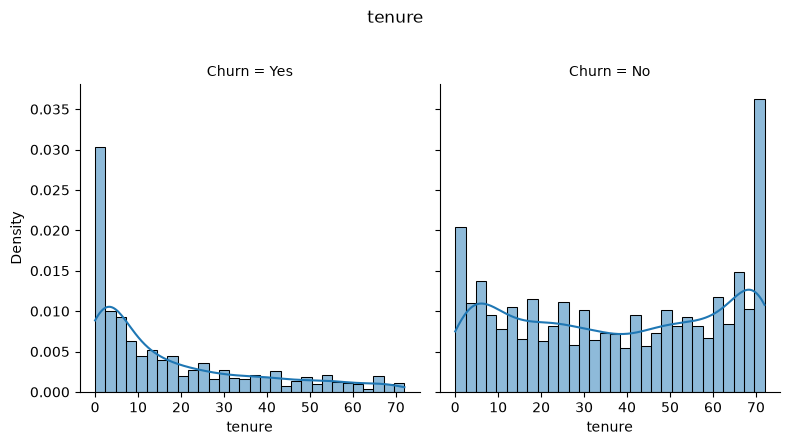

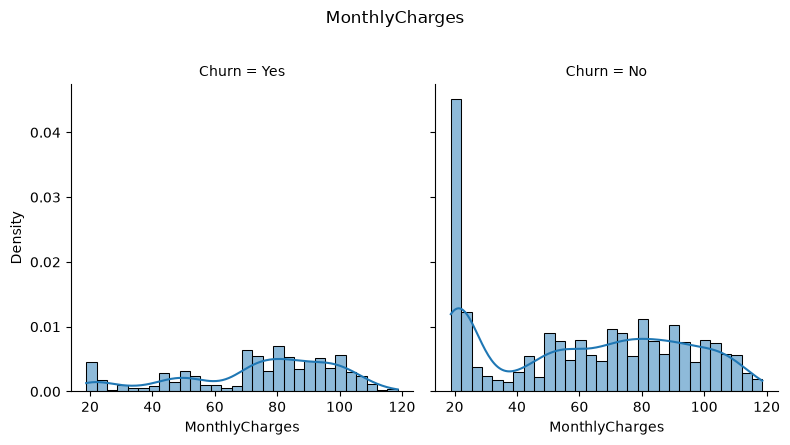

In [44]:
# Distribusi data tiap variabel numerikal berdasarkan target (Churn dan tidak Churn)
num_cols = df.select_dtypes(include='number').columns

for col in num_cols:
    num_hist_plot = sns.displot(data=df, x=col, col='Churn', stat='density',
                    kde=True, bins=30, height=4)
    num_hist_plot.fig.suptitle(col,y=1.1)
    plt.show()

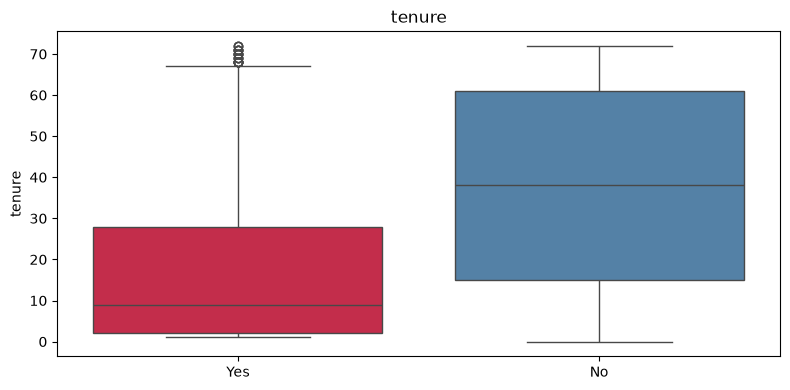

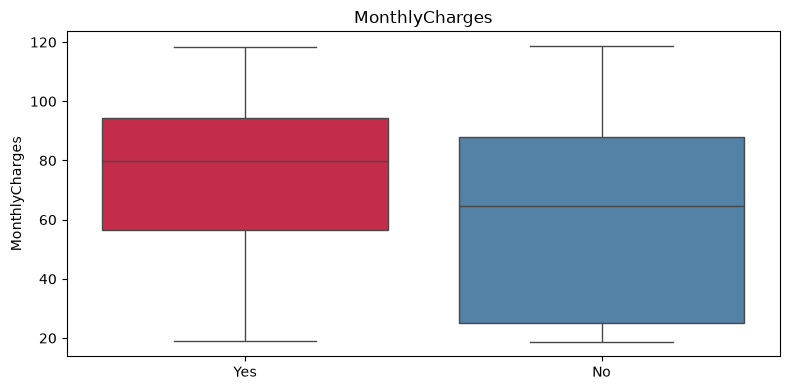

In [45]:
# Boxplot tiap variabel numerikal berdasarkan target (Churn dan tidak Churn)

for col in num_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df, x='Churn', y=col, hue='Churn',
                palette={'No':'steelblue','Yes': 'crimson'})
    plt.title(col)
    plt.xlabel('')
    plt.tight_layout()
    plt.show()

Dari histogram dan boxplot kolom numeric diatas, diperoleh bahwa persebaran data Churn dan tidak Churn pada feature `tenure` dan `MonthlyCharges` tidak terdistribusi dengan normal. Kita akan melakukan uji normalitas Kolmogorov-Smirnov untuk memastikan apakah feature tersebut berdistribusi normal atau tidak. Kita pilih menggunakan Kolmogorov-Smirnov karena ukuran sampel besar.

In [46]:
# Feature tenure, Churn = Yes

stat, pvalue = kstest(df[df['Churn'] == 'Yes']['tenure'], 'norm')

if pvalue > 0.05:
    # Ho
    print(f'pvalue={pvalue}. pvalue > 0.05. Gagal menolak Ho. Kita anggap data terdistribusi normal')
else:
    # Ha
    print(f'pvalue={pvalue}. pvalue < 0.05. Berhasil menolak Ho. Kita anggap data tidak terdistribusi normal')

pvalue=0.0. pvalue < 0.05. Berhasil menolak Ho. Kita anggap data tidak terdistribusi normal


In [47]:
# Feature tenure, Churn  No

stat, pvalue = kstest(df[df['Churn'] == 'No']['tenure'], 'norm')

if pvalue > 0.05:
    # Ho
    print(f'pvalue={pvalue}. pvalue > 0.05. Gagal menolak Ho. Kita anggap data terdistribusi normal')
else:
    # Ha
    print(f'pvalue={pvalue}. pvalue < 0.05. Berhasil menolak Ho. Kita anggap data tidak terdistribusi normal')

pvalue=0.0. pvalue < 0.05. Berhasil menolak Ho. Kita anggap data tidak terdistribusi normal


In [48]:
# Feature MonthlyCharges, Churn = Yes

stat, pvalue = kstest(df[df['Churn'] == 'Yes']['MonthlyCharges'], 'norm')

if pvalue > 0.05:
    # Ho
    print(f'pvalue={pvalue}. pvalue > 0.05. Gagal menolak Ho. Kita anggap data terdistribusi normal')
else:
    # Ha
    print(f'pvalue={pvalue}. pvalue < 0.05. Berhasil menolak Ho. Kita anggap data tidak terdistribusi normal')

pvalue=0.0. pvalue < 0.05. Berhasil menolak Ho. Kita anggap data tidak terdistribusi normal


In [49]:
# Feature MonthlyCharges, Churn = No

stat, pvalue = kstest(df[df['Churn'] == 'No']['MonthlyCharges'], 'norm')

if pvalue > 0.05:
    # Ho
    print(f'pvalue={pvalue}. pvalue > 0.05. Gagal menolak Ho. Kita anggap data terdistribusi normal')
else:
    # Ha
    print(f'pvalue={pvalue}. pvalue < 0.05. Berhasil menolak Ho. Kita anggap data tidak terdistribusi normal')

pvalue=0.0. pvalue < 0.05. Berhasil menolak Ho. Kita anggap data tidak terdistribusi normal


Uji normalitas menggunakan Kolmogorov-Smirnov diatas menunjukan bahwa data churn dan tidak churn pada feature `tenure` dan `MonthlyChargers` tidak terdistribusi normal.

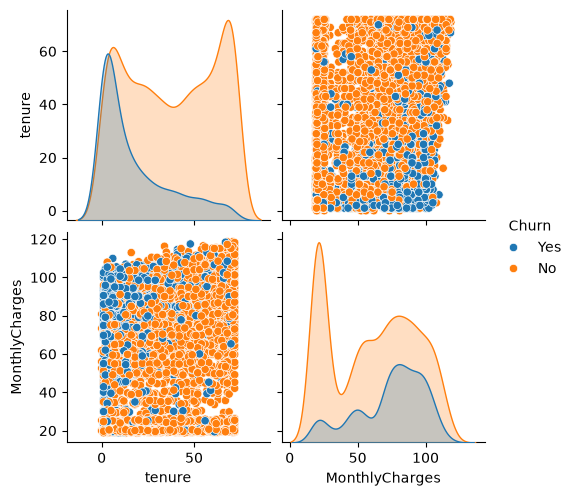

In [50]:
# Scatter plot untuk variabel numerikal
num_columns = df.select_dtypes(include='number').columns.tolist()

sns.pairplot(df[num_columns+['Churn']], hue='Churn')
plt.show()

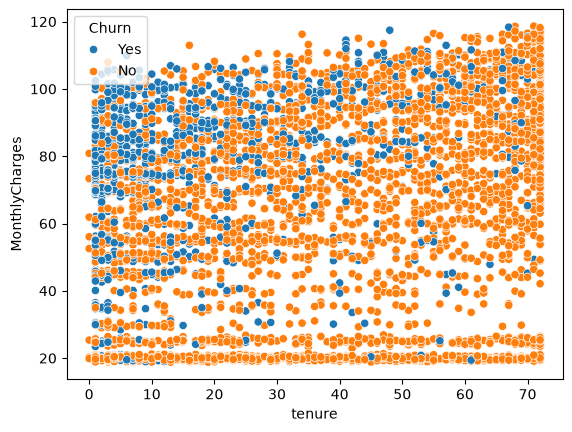

In [51]:
sns.scatterplot(data=df, x='tenure', y='MonthlyCharges', hue='Churn')
plt.show()

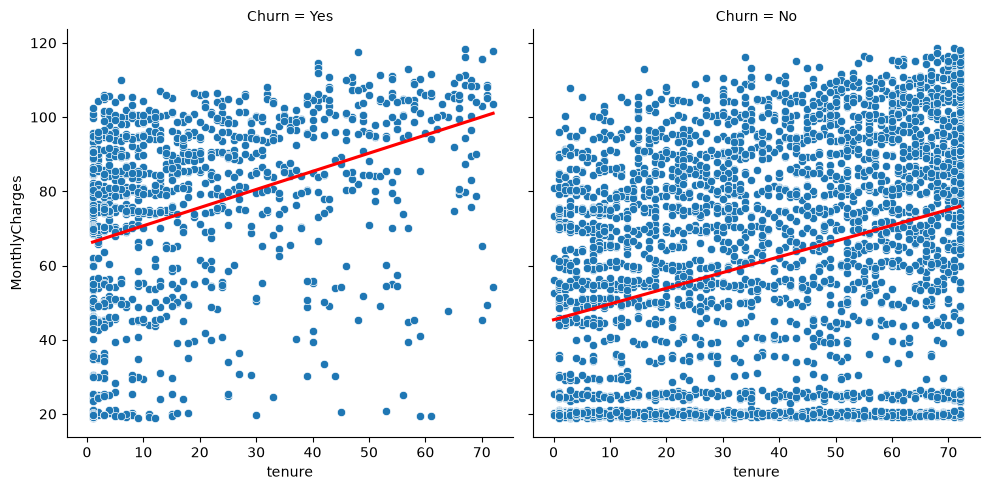

In [52]:
num_sctr=sns.relplot(data=df, x='tenure', y='MonthlyCharges', col='Churn', kind='scatter')
num_sctr.map_dataframe(sns.regplot, x='tenure', y='MonthlyCharges', scatter=False, ci=None, color='red')
plt.show()

Scatter plot diatas menunjukkan hubungan 2 feature numeric, yaitu `tenure` dan `MonthlyCharges` yang dibedakan berdasarkan target `Churn`.<br>
- Scatter plot sisi kiri menunjukkan hubungan feature `tenure` dan `MonthlyCharges` berdasarkan target yang churn (Churn = Yes)
- Scatter plot sisi kanan menunjukkan hubungan feature `tenure` dan `MonthlyCharges` berdasarkan target yang churn (Churn = No)<br>

Dari 2 scatter plot diatas diperoleh bahwa:<br>
- Kelompok Churn dan tidak Churn memiliki tren arah hubungan yang positif, ditunjukkan dengan garis merah regresi naik di kedua plot.
- Hubungan dari `tenure` dan `MonthlyCharges` yaitu makin lama berlangganan (`tenure` makin tinggi), maka tagihan bulanan cenderung makin tinggi (`MonthlyCharges` makin tinggi).
- Kemiringan garis regresi kelompok Churn dan tidak Churn mirip namun berbeda. Kenaikan kedua garis mirip, namun garis kelompok Churn lebih tinggi sepanjang sumbu x.


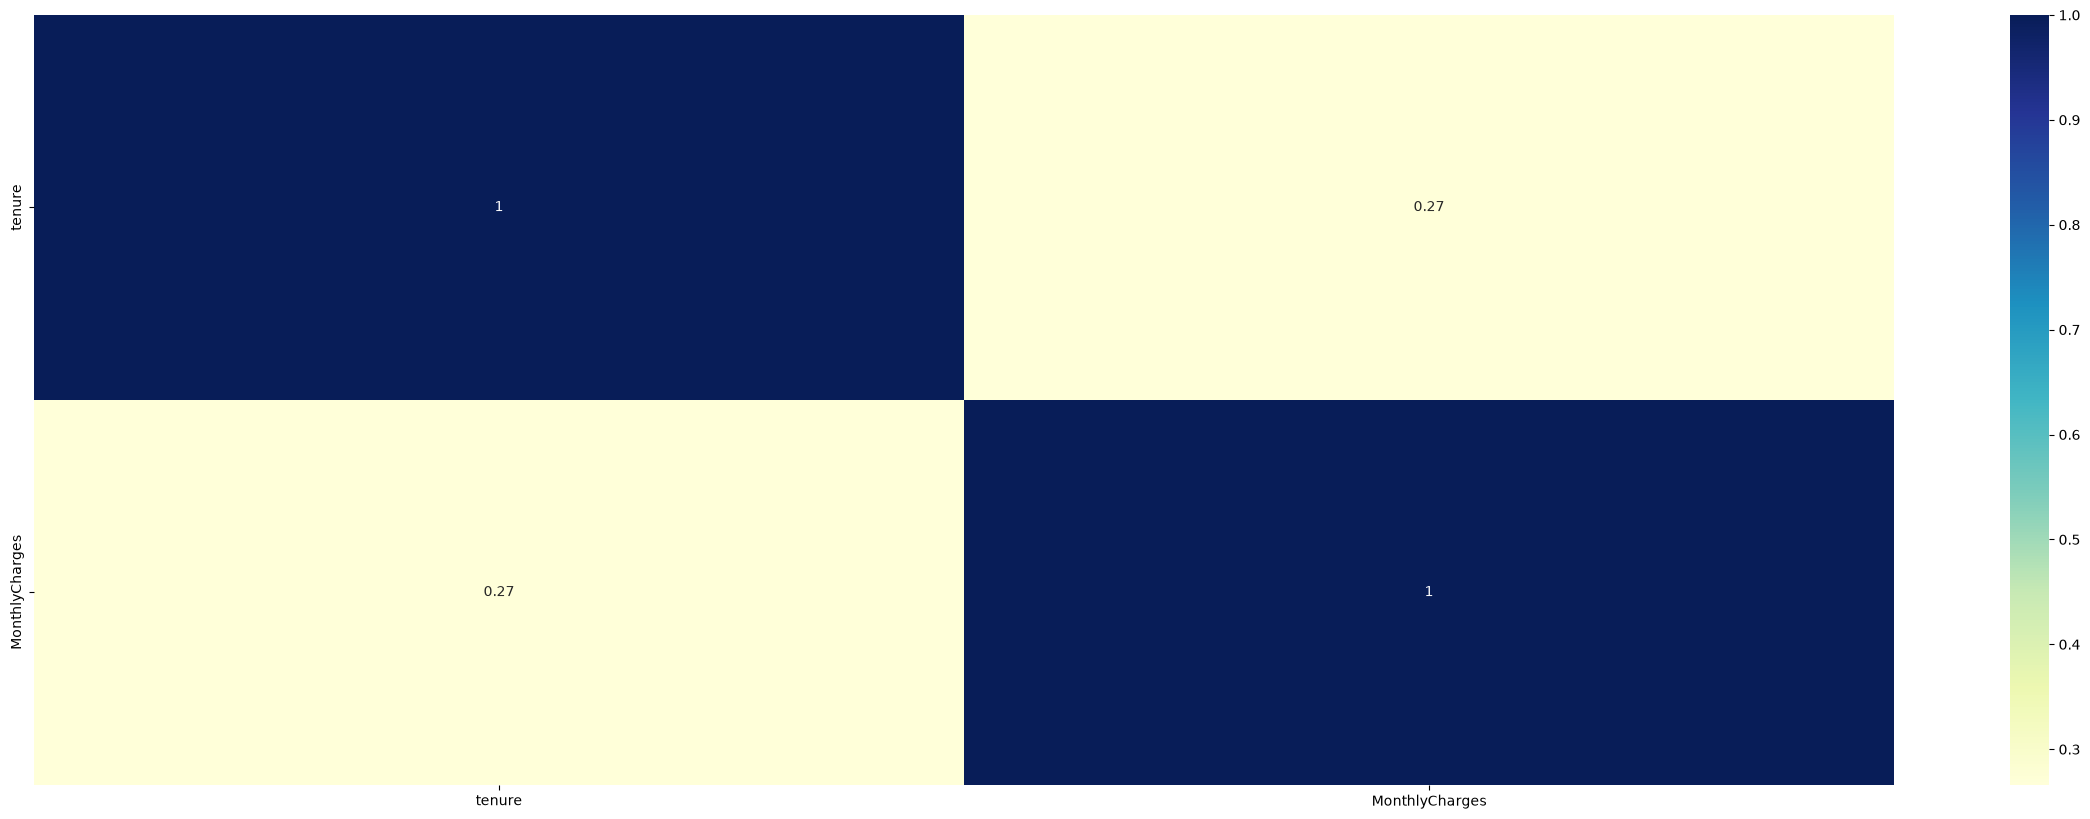

In [53]:
# Heatmap untuk feature numerikal

plt.figure(figsize=(30, 10))
sns.heatmap(df.corr(numeric_only=True, method='spearman'), annot=True, cmap='YlGnBu')
plt.show()

Heatmap diatas menunjukkan bahwa feature `tenure` dan `MonthlyCharges` memiliki korelasi 0.27. Nilai korelasi ini berarti kedua feature tersebut memiliki hubungan ke arah yang positif namun korelasinya lemah.

               count      mean
tenure_bin                    
(-0.001, 9.0]   1308  0.506116
(9.0, 29.0]     1186  0.287521
(29.0, 55.0]    1204  0.183555
(55.0, 72.0]    1232  0.074675


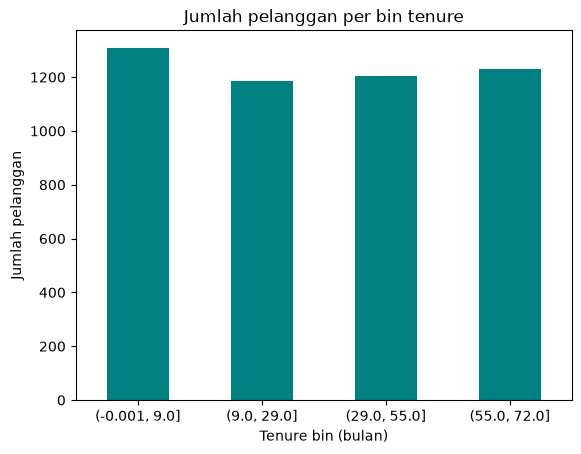

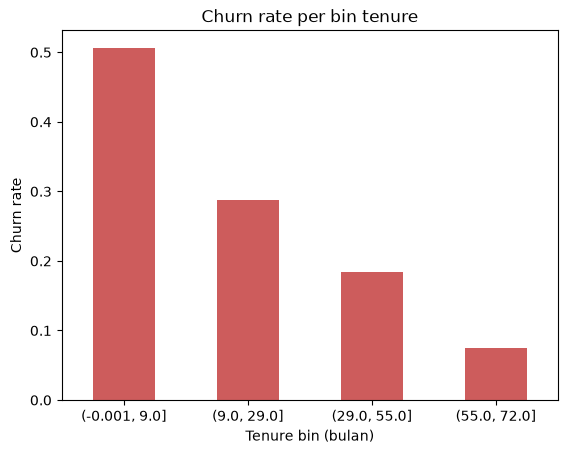

In [ ]:
# Distribusi dan proporsi data berdasarkan kelompok tenure
df_copy = df.copy()
df_copy['tenure_bin'] = pd.qcut(df_copy['tenure'], q=4)
df_copy['Churn'] = df_copy['Churn'].map({'No': 0, 'Yes': 1})

summary = df_copy.groupby('tenure_bin')['Churn'].agg(['count','mean'])
print(summary)

summary['count'].plot(kind='bar', color='teal')
plt.title('Jumlah pelanggan per bin tenure')
plt.xlabel('Tenure bin (bulan)')
plt.ylabel('Jumlah pelanggan')
plt.xticks(rotation=0)
plt.show()

summary['mean'].plot(kind='bar', color='indianred')
plt.title('Churn rate per bin tenure')
plt.xlabel('Tenure bin (bulan)')
plt.ylabel('Churn rate')
plt.xticks(rotation=0)
plt.show()

Barplot diatas merupakan distribusi tiap kelompok tenure. Feature tenure dibagi berdasarkan kuantil. Barplot pertama menunjukkan distribusi pelanggan tiap bin tenure. Jumlah pelanggan tiap bin tenure hampir sama (berada di rentang 1186-1308). Barplot kedua menunjukkan churn rate tiap bin tenure. Kelompok tenure paling pendek memiliki churn rate yang paling tinggi yaitu 0.506. Churn rate terus menurun sampai kelompok tenure paling panjang memiliki churn rate yang paling krcil yaitu 0.074. Dari barplot diatas, diperoleh bahwa risiko pelanggan untuk churn ada di tenure paling pendek atau di fase awal dibandingkan dengan pelanggan yang berada di kelompok tenure yang lebih panjang.

# **Define X and y**

Pada bagian ini kita mendefinisikan X yang berisi semua variabel sebagai feature dan Y sebagai target.<br>
- Dataframe X berisi semua kolom selain kolom `Churn` karena pada dataset tidak ada kolom sebagai primary key seperti customer ID
- Dataframe y berisi kolom `Churn` sebagai target dan ubah nilai pada kolom tersebut menjadi numerik.<br>
`Yes` diubah menjadi `1`.<br>
`No` diubah menjadi `0`.

In [59]:
X = df.drop(columns=['Churn'])
X

,Dependents,tenure,OnlineSecurity,OnlineBackup,InternetService,DeviceProtection,TechSupport,Contract,PaperlessBilling,MonthlyCharges
0,Yes,9,No,No,DSL,Yes,Yes,Month-to-month,Yes,72.90
1,No,14,No,Yes,Fiber optic,Yes,No,Month-to-month,Yes,82.65
2,No,64,Yes,No,DSL,Yes,Yes,Two year,No,47.85
3,No,72,Yes,Yes,DSL,Yes,Yes,Two year,No,69.65
4,No,3,No internet service,No internet service,No,No internet service,No internet service,Month-to-month,Yes,23.60
...,...,...,...,...,...,...,...,...,...,...
4925,No,15,No,No,Fiber optic,Yes,Yes,Month-to-month,Yes,103.45
4926,Yes,10,No,No,Fiber optic,Yes,Yes,Month-to-month,Yes,91.10
4927,No,58,No internet service,No internet service,No,No internet service,No internet service,Two year,No,20.75
4928,No,1,No,No,Fiber optic,No,No,Month-to-month,Yes,69.75


In [60]:
y = df['Churn']
y = y.map({'No': 0, 'Yes': 1})
y

0       1
1       0
2       1
3       0
4       0
       ..
4925    0
4926    0
4927    0
4928    1
4929    0
Name: Churn, Length: 4930, dtype: int64

# **Train Test Split**

Pada bagian ini, kita membagi data train dan test dengan proporsi `80:20`

In [61]:
X_train, X_test, y_train, y_test = train_test_split(X,
                 y,
                 random_state=0,
                 test_size=0.2,
                 stratify=y)

In [62]:
y.value_counts() / len(y)

Churn
0    0.733063
1    0.266937
Name: count, dtype: float64

# **Preprocessing**

In [63]:
X

,Dependents,tenure,OnlineSecurity,OnlineBackup,InternetService,DeviceProtection,TechSupport,Contract,PaperlessBilling,MonthlyCharges
0,Yes,9,No,No,DSL,Yes,Yes,Month-to-month,Yes,72.90
1,No,14,No,Yes,Fiber optic,Yes,No,Month-to-month,Yes,82.65
2,No,64,Yes,No,DSL,Yes,Yes,Two year,No,47.85
3,No,72,Yes,Yes,DSL,Yes,Yes,Two year,No,69.65
4,No,3,No internet service,No internet service,No,No internet service,No internet service,Month-to-month,Yes,23.60
...,...,...,...,...,...,...,...,...,...,...
4925,No,15,No,No,Fiber optic,Yes,Yes,Month-to-month,Yes,103.45
4926,Yes,10,No,No,Fiber optic,Yes,Yes,Month-to-month,Yes,91.10
4927,No,58,No internet service,No internet service,No,No internet service,No internet service,Two year,No,20.75
4928,No,1,No,No,Fiber optic,No,No,Month-to-month,Yes,69.75


In [64]:
X.describe()

,tenure,MonthlyCharges
count,4930.000000,4930.000000
mean,32.401217,64.883032
std,24.501193,29.923960
min,0.000000,18.800000
25%,9.000000,37.050000
50%,29.000000,70.350000
75%,55.000000,89.850000
max,72.000000,118.650000


Pada bagian ini, kita akan melakukan feature encoding untuk semua feature yang kita miliki. Yang akan dilakukan sebagai berikut.
1. Merubah feature `Dependents` menggunakan One Hot Encoding karena feature ini tidak memiliki urutan/tidak ordinal dan jumlah uniquenya hanya sedikit.
2. Merubah feature `tenure` menggunakan robust scaler karena distribusi tidak normal dan binning.
3. Merubah feature `OnlineSecurity` menggunakan One Hot Encoding karena feature ini tidak memiliki urutan/tidak ordinal dan jumlah uniquenya hanya sedikit.
4. Merubah feature `OnlineBackup` menggunakan One Hot Encoding karena feature ini tidak memiliki urutan/tidak ordinal dan jumlah uniquenya hanya sedikit.
5. Merubah feature `InternetService` menggunakan One Hot Encoding karena feature ini tidak memiliki urutan/tidak ordinal dan jumlah uniquenya hanya sedikit.
6. Merubah feature `DeviceProtection` menggunakan One Hot Encoding karena feature ini tidak memiliki urutan/tidak ordinal dan jumlah uniquenya hanya sedikit.
7. Merubah feature `TechSupport` menggunakan One Hot Encoding karena feature ini tidak memiliki urutan/tidak ordinal dan jumlah uniquenya hanya sedikit.
8. Merubah feature `Contract` menggunakan One Hot Encoding karena feature ini tidak memiliki urutan/tidak ordinal dan jumlah uniquenya hanya sedikit.
9. Merubah feature `PaperlessBilling` menggunakan One Hot Encoding karena feature ini tidak memiliki urutan/tidak ordinal dan jumlah uniquenya hanya sedikit.
10. Merubah feature `MonthlyCharges` menggunakan robust scaler karena distribusi tidak normal dan skala feature ini berbeda jauh (18.8-118.65).

Selanjutnya, kita akan membuat 2 transformer. Perbedaan kedua transformer terletak pada treatment feature `tenure`. Transformer pertama, treatment untuk feature `tenure` dengan melakukan feature encoding berupa robust scaler. Transformer kedua, treatment untuk feature `tenure` dengan melakukan feature encoding berubah binning. Kita membuat 2 transformer karena kebutuhan model linear dan model non-linear saat cross validation berbeda.
- Model seperti `LogisticRegression` dan `KNN` sensitif pada skala fitur sehingga model ini lebih cocok jika feature seperti `tenure` dilakukan binning.
- Model seperti `DecisionTree`, `AdaBoost`, `RandomForest`, dan `GradientBoosting` tidak perlu binning pada transformer karena model tersebut sudah membuat splitnya sendiri.

In [65]:
transformer = ColumnTransformer([
    ('onehot', OneHotEncoder(drop='first'), ['Dependents', 'OnlineSecurity', 'OnlineBackup', 'InternetService',
                                             'DeviceProtection', 'TechSupport', 'Contract', 'PaperlessBilling']),
    ('scaler_continuous', RobustScaler(), ['MonthlyCharges']),
    ('scaler_discrete', RobustScaler(), ['tenure'])
], remainder='passthrough')


transformer_bin = ColumnTransformer([
    ('onehot', OneHotEncoder(drop='first'), ['Dependents', 'OnlineSecurity', 'OnlineBackup', 'InternetService',
                                             'DeviceProtection', 'TechSupport', 'Contract', 'PaperlessBilling']),
    ('scaler_continuous', RobustScaler(), ['MonthlyCharges']),
    ('bin_or_scale', KBinsDiscretizer(strategy='quantile', encode='onehot'), ['tenure'])
], remainder='passthrough')

display(transformer)
display(transformer_bin)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehot', ...), ('scaler_continuous', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transforme

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehot', ...), ('scaler_continuous', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transforme

In [66]:
testing = pd.DataFrame(transformer.fit_transform(X_train), columns=transformer.get_feature_names_out())
testing.head()

,onehot__Dependents_Yes,onehot__OnlineSecurity_No internet service,onehot__OnlineSecurity_Yes,onehot__OnlineBackup_No internet service,onehot__OnlineBackup_Yes,onehot__InternetService_Fiber optic,onehot__InternetService_No,onehot__DeviceProtection_No internet service,onehot__DeviceProtection_Yes,onehot__TechSupport_No internet service,onehot__TechSupport_Yes,onehot__Contract_One year,onehot__Contract_Two year,onehot__PaperlessBilling_Yes,scaler_continuous__MonthlyCharges,scaler_discrete__tenure
0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.384330,-0.500000
1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.191470,0.891304
2,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.260083,-0.152174
3,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,-0.927677,-0.608696
4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,-0.273992,-0.326087


In [67]:
testing_bin = pd.DataFrame(transformer_bin.fit_transform(X_train), columns=transformer_bin.get_feature_names_out())
testing_bin.head()

,onehot__Dependents_Yes,onehot__OnlineSecurity_No internet service,onehot__OnlineSecurity_Yes,onehot__OnlineBackup_No internet service,onehot__OnlineBackup_Yes,onehot__InternetService_Fiber optic,onehot__InternetService_No,onehot__DeviceProtection_No internet service,onehot__DeviceProtection_Yes,onehot__TechSupport_No internet service,onehot__TechSupport_Yes,onehot__Contract_One year,onehot__Contract_Two year,onehot__PaperlessBilling_Yes,scaler_continuous__MonthlyCharges,bin_or_scale__tenure_0.0,bin_or_scale__tenure_1.0,bin_or_scale__tenure_2.0,bin_or_scale__tenure_3.0,bin_or_scale__tenure_4.0
0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.384330,0.0,1.0,0.0,0.0,0.0
1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.191470,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.260083,0.0,0.0,1.0,0.0,0.0
3,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,-0.927677,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,-0.273992,0.0,1.0,0.0,0.0,0.0


# **Cross Validation (Model Benchmark)**

In [68]:
# define model
logreg = LogisticRegression(random_state=0)
knn = KNeighborsClassifier()
tree = DecisionTreeClassifier(random_state=0)

# ensemble various
voting = VotingClassifier(estimators=[('clf1', logreg),
                                      ('clf2', knn),
                                      ('clf3', tree)],
                                      voting='soft')

stacking = StackingClassifier(estimators=[('clf1', logreg),
                                          ('clf2', knn),
                                          ('clf3', tree)])

# Scaling data
scaler = StandardScaler()

# ensemble similar
bagging= BaggingClassifier(random_state=0, estimator=DecisionTreeClassifier(), n_estimators=100)
rf = RandomForestClassifier(random_state=0)
adaboost = AdaBoostClassifier(random_state=0)
gboost = GradientBoostingClassifier(random_state=0)

**1. Cek score tiap model dengan tranformer tanpa binning**

Pada tahap ini dilakukan pengecekan skor tiap model dengan transformer tanpa binning, yaitu feature `tenure` hanya dilakukan feature encoding dengan RobustScaler saja.

In [69]:
list_model = [logreg, knn, tree, voting, stacking, bagging, rf, adaboost, gboost]
list_model_all = []

skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

f2 = make_scorer(fbeta_score, beta=2)

scoring = {
    'recall': 'recall',
    'precision': 'precision',
    'f2': f2,
    'avg_precision': 'average_precision',
}

for model in list_model:
    # pipeline
    pipe_prep_model =  Pipeline([
        ('preprocessing', transformer),
        ('modeling', model)
    ])

    # cross val
    crossval = cross_validate(estimator=pipe_prep_model,
                    X = X_train,
                    y = y_train,
                    cv = skfold,
                    scoring = scoring,
                    return_train_score=True,
                    n_jobs=-1,
                    error_score='raise')
    
    # matrics
    list_model_all.append({
        'algo': type(model).__name__,
        'f2_mean': crossval['test_f2'].mean(),
        'f2_std': crossval['test_f2'].std(),
        'recall': crossval['test_recall'].mean(),
        'precision': crossval['test_precision'].mean(),
        'avg_precision': crossval['test_avg_precision'].mean(),
        'f2_train': crossval['train_f2'].mean(),
        'diff_f2': crossval['train_f2'].mean() - crossval['test_f2'].mean(),
        'all_f2': crossval['test_f2'].round(2),
    })


df_score = pd.DataFrame(list_model_all).sort_values('f2_mean', ascending=False)

df_score

,algo,f2_mean,f2_std,recall,precision,avg_precision,f2_train,diff_f2,all_f2
0,LogisticRegression,0.552629,0.018863,0.534620,0.639162,0.657851,0.550150,-0.002479,"[0.56, 0.57, 0.57, 0.54, 0.52]"
8,GradientBoostingClassifier,0.538398,0.025321,0.517545,0.643555,0.651970,0.605122,0.066723,"[0.55, 0.51, 0.58, 0.53, 0.52]"
4,StackingClassifier,0.522587,0.028201,0.500424,0.637899,0.657070,0.580996,0.058409,"[0.54, 0.51, 0.57, 0.5, 0.5]"
3,VotingClassifier,0.517261,0.010831,0.506161,0.567847,0.610356,0.894893,0.377631,"[0.51, 0.52, 0.53, 0.52, 0.5]"
5,BaggingClassifier,0.504932,0.017752,0.487195,0.594296,0.593774,0.988366,0.483434,"[0.49, 0.49, 0.53, 0.5, 0.52]"
2,DecisionTreeClassifier,0.502547,0.023794,0.507086,0.486058,0.381748,0.982937,0.480390,"[0.5, 0.5, 0.54, 0.5, 0.46]"
6,RandomForestClassifier,0.487577,0.015873,0.468206,0.586687,0.596567,0.988269,0.500691,"[0.49, 0.46, 0.5, 0.48, 0.5]"
7,AdaBoostClassifier,0.479564,0.025434,0.447267,0.676440,0.642460,0.481870,0.002306,"[0.49, 0.51, 0.48, 0.49, 0.43]"
1,KNeighborsClassifier,0.477998,0.025015,0.463444,0.549829,0.526769,0.637673,0.159674,"[0.48, 0.46, 0.5, 0.51, 0.44]"


**2. Cek score tiap model dengan tranformer dengan binning**

Pada tahap ini dilakukan pengecekan skor tiap model dengan transformer yang dibinning, yaitu feature `tenure` hanya dilakukan feature encoding dengan binning saja.

In [70]:
list_model = [logreg, knn, tree, voting, stacking, bagging, rf, adaboost, gboost]
list_model_all_bin = []

skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

f2 = make_scorer(fbeta_score, beta=2)

scoring = {
    'recall': 'recall',
    'precision': 'precision',
    'f2': f2,
    'avg_precision': 'average_precision',
}

for model in list_model:
    # pipeline
    pipe_prep_model_bin =  Pipeline([
        ('preprocessing', transformer_bin),
        ('modeling', model)
    ])

    # cross val
    crossval_bin = cross_validate(estimator=pipe_prep_model_bin,
                    X = X_train,
                    y = y_train,
                    cv = skfold,
                    scoring = scoring,
                    return_train_score=True,
                    n_jobs=-1,
                    error_score='raise')
    
    # matrics
    list_model_all_bin.append({
        'algo': type(model).__name__,
        'f2_mean': crossval_bin['test_f2'].mean(),
        'f2_std': crossval_bin['test_f2'].std(),
        'recall': crossval_bin['test_recall'].mean(),
        'precision': crossval_bin['test_precision'].mean(),
        'avg_precision': crossval_bin['test_avg_precision'].mean(),
        'f2_train': crossval_bin['train_f2'].mean(),
        'diff_f2': crossval_bin['train_f2'].mean() - crossval_bin['test_f2'].mean(),
        'all_f2': crossval_bin['test_f2'].round(2),
    })


df_score_bin = pd.DataFrame(list_model_all_bin).sort_values('f2_mean', ascending=False)

df_score_bin

,algo,f2_mean,f2_std,recall,precision,avg_precision,f2_train,diff_f2,all_f2
8,GradientBoostingClassifier,0.549151,0.022768,0.528946,0.649710,0.653773,0.612534,0.063384,"[0.56, 0.52, 0.59, 0.53, 0.54]"
0,LogisticRegression,0.544495,0.025281,0.523218,0.650718,0.661610,0.552865,0.008369,"[0.56, 0.54, 0.58, 0.52, 0.52]"
4,StackingClassifier,0.538183,0.014222,0.513753,0.665435,0.663898,0.586949,0.048766,"[0.54, 0.54, 0.56, 0.53, 0.52]"
3,VotingClassifier,0.527419,0.036023,0.515662,0.581000,0.619821,0.876847,0.349428,"[0.53, 0.48, 0.59, 0.52, 0.52]"
5,BaggingClassifier,0.521187,0.042083,0.508061,0.582747,0.590331,0.970120,0.448933,"[0.57, 0.45, 0.56, 0.52, 0.51]"
7,AdaBoostClassifier,0.520668,0.034913,0.495667,0.653941,0.652528,0.532529,0.011860,"[0.57, 0.52, 0.54, 0.52, 0.46]"
2,DecisionTreeClassifier,0.508593,0.029650,0.509023,0.507559,0.394845,0.960246,0.451653,"[0.52, 0.46, 0.55, 0.51, 0.5]"
6,RandomForestClassifier,0.499436,0.041239,0.486206,0.561062,0.584470,0.969245,0.469809,"[0.56, 0.44, 0.53, 0.48, 0.49]"
1,KNeighborsClassifier,0.498267,0.046541,0.486315,0.558893,0.536805,0.655139,0.156872,"[0.48, 0.42, 0.53, 0.53, 0.53]"


# **Resampling**

Pada tahap ini, dilakukan resampling karena jumlah data antara churn dan tidak churn tidak seimbang. Pada tiap metode resampling diberi parameter `random_state=0` agar hasil selalu sama.

In [71]:
smote = SMOTE(random_state=0)
nm = NearMiss()
ros = RandomOverSampler(random_state=0)
rus = RandomUnderSampler(random_state=0)

Pada bagian ini, kita coba resampling pakai `SMOTE` dan `RandomOverSampler`. Kedua metode ini dipilih karena cara kerja `SMOTE` adalah membuat data baru buatan dan cara kerja `RandomoOverSampler` adalah menduplikasi data dari kelas minoritas secara acak.<br>

**1. Cek score tiap model dengan tranformer tanpa binning**

Pertama, kita coba resampling menggunakan metode `SMOTE`.

In [72]:
list_model = [logreg, knn, tree, voting, stacking, bagging, rf, adaboost, gboost]
list_model_all = []

skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

f2 = make_scorer(fbeta_score, beta=2)

scoring = {
    'recall': 'recall',
    'precision': 'precision',
    'f2': f2,
    'avg_precision': 'average_precision',
}

for model in list_model:
    # pipeline
    pipe_prep_model =  Pipeline([
        ('preprocessing', transformer),
        ('resampling', smote),
        ('modeling', model)
    ])

    # cross val
    crossval = cross_validate(estimator=pipe_prep_model,
                    X = X_train,
                    y = y_train,
                    cv = skfold,
                    scoring = scoring,
                    return_train_score=True,
                    n_jobs=-1,
                    error_score='raise')
    
    # matrics
    list_model_all.append({
        'algo': type(model).__name__,
        'f2_mean': crossval['test_f2'].mean(),
        'f2_std': crossval['test_f2'].std(),
        'recall': crossval['test_recall'].mean(),
        'precision': crossval['test_precision'].mean(),
        'avg_precision': crossval['test_avg_precision'].mean(),
        'f2_train': crossval['train_f2'].mean(),
        'diff_f2': crossval['train_f2'].mean() - crossval['test_f2'].mean(),
        'all_f2': crossval['test_f2'].round(2),
    })


df_score_resampling = pd.DataFrame(list_model_all).sort_values('f2_mean', ascending=False)

df_score_resampling

,algo,f2_mean,f2_std,recall,precision,avg_precision,f2_train,diff_f2,all_f2
7,AdaBoostClassifier,0.719031,0.025944,0.799576,0.513556,0.646663,0.726505,0.007474,"[0.73, 0.74, 0.73, 0.73, 0.67]"
0,LogisticRegression,0.718731,0.013391,0.798691,0.513625,0.655782,0.726474,0.007742,"[0.71, 0.7, 0.74, 0.72, 0.72]"
8,GradientBoostingClassifier,0.698304,0.014992,0.758786,0.530122,0.655524,0.744060,0.045756,"[0.68, 0.71, 0.71, 0.71, 0.68]"
4,StackingClassifier,0.646213,0.024560,0.682803,0.532587,0.619346,0.874832,0.228620,"[0.63, 0.63, 0.69, 0.64, 0.63]"
3,VotingClassifier,0.627881,0.027878,0.665714,0.511825,0.616496,0.949963,0.322082,"[0.62, 0.6, 0.67, 0.64, 0.61]"
1,KNeighborsClassifier,0.627833,0.021126,0.682807,0.475373,0.495068,0.808898,0.181065,"[0.63, 0.6, 0.66, 0.61, 0.64]"
5,BaggingClassifier,0.621433,0.014806,0.643886,0.546550,0.590598,0.989853,0.368420,"[0.61, 0.63, 0.63, 0.64, 0.6]"
6,RandomForestClassifier,0.593069,0.009922,0.606847,0.545027,0.584871,0.989185,0.396116,"[0.59, 0.59, 0.6, 0.58, 0.6]"
2,DecisionTreeClassifier,0.570055,0.035155,0.595450,0.487625,0.401498,0.983226,0.413172,"[0.56, 0.52, 0.63, 0.59, 0.55]"


Kedua, kita coba resampling menggunakan  metode `RandomOverSampling`.

In [75]:
list_model = [logreg, knn, tree, voting, stacking, bagging, rf, adaboost, gboost]
list_model_all = []

skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

f2 = make_scorer(fbeta_score, beta=2)

scoring = {
    'recall': 'recall',
    'precision': 'precision',
    'f2': f2,
    'avg_precision': 'average_precision',
}

for model in list_model:
    # pipeline
    pipe_prep_model =  Pipeline([
        ('preprocessing', transformer),
        ('resampling', ros),
        ('modeling', model)
    ])

    # cross val
    crossval = cross_validate(estimator=pipe_prep_model,
                    X = X_train,
                    y = y_train,
                    cv = skfold,
                    scoring = scoring,
                    return_train_score=True,
                    n_jobs=-1,
                    error_score='raise')
    
    # matrics
    list_model_all.append({
        'algo': type(model).__name__,
        'f2_mean': crossval['test_f2'].mean(),
        'f2_std': crossval['test_f2'].std(),
        'recall': crossval['test_recall'].mean(),
        'precision': crossval['test_precision'].mean(),
        'avg_precision': crossval['test_avg_precision'].mean(),
        'f2_train': crossval['train_f2'].mean(),
        'diff_f2': crossval['train_f2'].mean() - crossval['test_f2'].mean(),
        'all_f2': crossval['test_f2'].round(2),
    })


df_score_resampling_ros = pd.DataFrame(list_model_all).sort_values('f2_mean', ascending=False)

df_score_resampling_ros

,algo,f2_mean,f2_std,recall,precision,avg_precision,f2_train,diff_f2,all_f2
7,AdaBoostClassifier,0.723887,0.018492,0.811018,0.506868,0.636494,0.733238,0.009351,"[0.74, 0.73, 0.71, 0.74, 0.69]"
0,LogisticRegression,0.722740,0.014485,0.804392,0.514513,0.654636,0.725493,0.002753,"[0.71, 0.71, 0.74, 0.73, 0.73]"
8,GradientBoostingClassifier,0.712210,0.022147,0.784396,0.520979,0.648188,0.770274,0.058064,"[0.69, 0.74, 0.73, 0.71, 0.68]"
1,KNeighborsClassifier,0.623645,0.022011,0.689415,0.451510,0.470669,0.813296,0.189651,"[0.65, 0.61, 0.65, 0.61, 0.6]"
3,VotingClassifier,0.601863,0.012541,0.623909,0.527764,0.601987,0.962267,0.360404,"[0.61, 0.61, 0.62, 0.59, 0.58]"
5,BaggingClassifier,0.566097,0.016325,0.570747,0.549856,0.576785,0.992526,0.426429,"[0.55, 0.56, 0.6, 0.56, 0.56]"
6,RandomForestClassifier,0.550196,0.015435,0.550815,0.548449,0.570334,0.992764,0.442567,"[0.56, 0.54, 0.55, 0.53, 0.57]"
4,StackingClassifier,0.512491,0.024941,0.509962,0.524352,0.592821,0.987857,0.475366,"[0.5, 0.55, 0.5, 0.53, 0.48]"
2,DecisionTreeClassifier,0.510391,0.023520,0.512805,0.502668,0.389860,0.991188,0.480796,"[0.5, 0.55, 0.51, 0.52, 0.48]"


**2. Cek score tiap model dengan tranformer dengan binning**

Pertama, kita coba resampling menggunakan metode `SMOTE`.

In [76]:
list_model = [logreg, knn, tree, voting, stacking, bagging, rf, adaboost, gboost]
list_model_all_bin = []

skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

f2 = make_scorer(fbeta_score, beta=2)

scoring = {
    'recall': 'recall',
    'precision': 'precision',
    'f2': f2,
    'avg_precision': 'average_precision',
}

for model in list_model:
    # pipeline
    pipe_prep_model_bin =  Pipeline([
        ('preprocessing', transformer_bin),
        ('resampling', smote),
        ('modeling', model)
    ])

    # cross val
    crossval_bin = cross_validate(estimator=pipe_prep_model_bin,
                    X = X_train,
                    y = y_train,
                    cv = skfold,
                    scoring = scoring,
                    return_train_score=True,
                    n_jobs=-1,
                    error_score='raise')
    
    # matrics
    list_model_all_bin.append({
        'algo': type(model).__name__,
        'f2_mean': crossval_bin['test_f2'].mean(),
        'f2_std': crossval_bin['test_f2'].std(),
        'recall': crossval_bin['test_recall'].mean(),
        'precision': crossval_bin['test_precision'].mean(),
        'avg_precision': crossval_bin['test_avg_precision'].mean(),
        'f2_train': crossval_bin['train_f2'].mean(),
        'diff_f2': crossval_bin['train_f2'].mean() - crossval_bin['test_f2'].mean(),
        'all_f2': crossval_bin['test_f2'].round(2),
    })


df_score_bin_resampling = pd.DataFrame(list_model_all_bin).sort_values('f2_mean', ascending=False)

df_score_bin_resampling

,algo,f2_mean,f2_std,recall,precision,avg_precision,f2_train,diff_f2,all_f2
0,LogisticRegression,0.726481,0.006097,0.811013,0.513415,0.660537,0.729984,0.003503,"[0.73, 0.72, 0.73, 0.72, 0.72]"
7,AdaBoostClassifier,0.719780,0.008258,0.794872,0.523209,0.653477,0.724143,0.004363,"[0.72, 0.74, 0.72, 0.72, 0.71]"
8,GradientBoostingClassifier,0.678267,0.012097,0.723656,0.543091,0.655842,0.721123,0.042856,"[0.68, 0.67, 0.69, 0.69, 0.66]"
4,StackingClassifier,0.644685,0.024906,0.679025,0.537501,0.627939,0.863404,0.218720,"[0.67, 0.6, 0.67, 0.63, 0.65]"
1,KNeighborsClassifier,0.643736,0.025077,0.698957,0.489986,0.501694,0.805080,0.161343,"[0.65, 0.62, 0.67, 0.61, 0.66]"
3,VotingClassifier,0.622541,0.035708,0.652431,0.526690,0.622304,0.940628,0.318087,"[0.65, 0.56, 0.66, 0.62, 0.63]"
5,BaggingClassifier,0.603132,0.034995,0.618222,0.549825,0.584776,0.972651,0.369519,"[0.64, 0.55, 0.64, 0.59, 0.6]"
2,DecisionTreeClassifier,0.569527,0.033656,0.591650,0.495790,0.405991,0.960835,0.391308,"[0.59, 0.51, 0.61, 0.56, 0.58]"
6,RandomForestClassifier,0.567102,0.033319,0.570752,0.553816,0.576306,0.973568,0.406465,"[0.62, 0.52, 0.57, 0.55, 0.58]"


Kedua, kita coba resampling menggunakan  metode `RandomOverSampling`.

In [77]:
list_model = [logreg, knn, tree, voting, stacking, bagging, rf, adaboost, gboost]
list_model_all_bin = []

skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

f2 = make_scorer(fbeta_score, beta=2)

scoring = {
    'recall': 'recall',
    'precision': 'precision',
    'f2': f2,
    'avg_precision': 'average_precision',
}

for model in list_model:
    # pipeline
    pipe_prep_model_bin =  Pipeline([
        ('preprocessing', transformer_bin),
        ('resampling', ros),
        ('modeling', model)
    ])

    # cross val
    crossval_bin = cross_validate(estimator=pipe_prep_model_bin,
                    X = X_train,
                    y = y_train,
                    cv = skfold,
                    scoring = scoring,
                    return_train_score=True,
                    n_jobs=-1,
                    error_score='raise')
    
    # matrics
    list_model_all_bin.append({
        'algo': type(model).__name__,
        'f2_mean': crossval_bin['test_f2'].mean(),
        'f2_std': crossval_bin['test_f2'].std(),
        'recall': crossval_bin['test_recall'].mean(),
        'precision': crossval_bin['test_precision'].mean(),
        'avg_precision': crossval_bin['test_avg_precision'].mean(),
        'f2_train': crossval_bin['train_f2'].mean(),
        'diff_f2': crossval_bin['train_f2'].mean() - crossval_bin['test_f2'].mean(),
        'all_f2': crossval_bin['test_f2'].round(2),
    })


df_score_bin_resampling_ros = pd.DataFrame(list_model_all_bin).sort_values('f2_mean', ascending=False)

df_score_bin_resampling_ros

,algo,f2_mean,f2_std,recall,precision,avg_precision,f2_train,diff_f2,all_f2
7,AdaBoostClassifier,0.725740,0.011826,0.806278,0.518729,0.652458,0.727091,0.001351,"[0.73, 0.73, 0.72, 0.74, 0.71]"
0,LogisticRegression,0.725151,0.007221,0.808179,0.514476,0.658244,0.728378,0.003227,"[0.73, 0.71, 0.73, 0.73, 0.72]"
8,GradientBoostingClassifier,0.706478,0.008333,0.778718,0.515523,0.650411,0.764236,0.057757,"[0.71, 0.7, 0.72, 0.7, 0.7]"
1,KNeighborsClassifier,0.642858,0.030787,0.706509,0.473116,0.485508,0.818793,0.175935,"[0.66, 0.62, 0.69, 0.6, 0.64]"
3,VotingClassifier,0.596018,0.039170,0.614430,0.532596,0.612607,0.952672,0.356655,"[0.63, 0.53, 0.64, 0.61, 0.57]"
5,BaggingClassifier,0.556645,0.042892,0.564071,0.529044,0.564848,0.981733,0.425087,"[0.62, 0.5, 0.59, 0.54, 0.54]"
6,RandomForestClassifier,0.527760,0.044953,0.527998,0.527208,0.554567,0.981589,0.453829,"[0.61, 0.47, 0.53, 0.5, 0.53]"
4,StackingClassifier,0.518188,0.040495,0.517563,0.521405,0.611401,0.975913,0.457725,"[0.55, 0.46, 0.56, 0.55, 0.48]"
2,DecisionTreeClassifier,0.513914,0.042200,0.516610,0.503795,0.395929,0.979719,0.465805,"[0.55, 0.45, 0.55, 0.54, 0.48]"


In [78]:
display(
    df_score_resampling.head(3),
    df_score_resampling_ros.head(3),
    df_score_bin_resampling.head(3),
    df_score_bin_resampling_ros.head(3))

,algo,f2_mean,f2_std,recall,precision,avg_precision,f2_train,diff_f2,all_f2
7,AdaBoostClassifier,0.719031,0.025944,0.799576,0.513556,0.646663,0.726505,0.007474,"[0.73, 0.74, 0.73, 0.73, 0.67]"
0,LogisticRegression,0.718731,0.013391,0.798691,0.513625,0.655782,0.726474,0.007742,"[0.71, 0.7, 0.74, 0.72, 0.72]"
8,GradientBoostingClassifier,0.698304,0.014992,0.758786,0.530122,0.655524,0.744060,0.045756,"[0.68, 0.71, 0.71, 0.71, 0.68]"


,algo,f2_mean,f2_std,recall,precision,avg_precision,f2_train,diff_f2,all_f2
7,AdaBoostClassifier,0.723887,0.018492,0.811018,0.506868,0.636494,0.733238,0.009351,"[0.74, 0.73, 0.71, 0.74, 0.69]"
0,LogisticRegression,0.722740,0.014485,0.804392,0.514513,0.654636,0.725493,0.002753,"[0.71, 0.71, 0.74, 0.73, 0.73]"
8,GradientBoostingClassifier,0.712210,0.022147,0.784396,0.520979,0.648188,0.770274,0.058064,"[0.69, 0.74, 0.73, 0.71, 0.68]"


,algo,f2_mean,f2_std,recall,precision,avg_precision,f2_train,diff_f2,all_f2
0,LogisticRegression,0.726481,0.006097,0.811013,0.513415,0.660537,0.729984,0.003503,"[0.73, 0.72, 0.73, 0.72, 0.72]"
7,AdaBoostClassifier,0.719780,0.008258,0.794872,0.523209,0.653477,0.724143,0.004363,"[0.72, 0.74, 0.72, 0.72, 0.71]"
8,GradientBoostingClassifier,0.678267,0.012097,0.723656,0.543091,0.655842,0.721123,0.042856,"[0.68, 0.67, 0.69, 0.69, 0.66]"


,algo,f2_mean,f2_std,recall,precision,avg_precision,f2_train,diff_f2,all_f2
7,AdaBoostClassifier,0.725740,0.011826,0.806278,0.518729,0.652458,0.727091,0.001351,"[0.73, 0.73, 0.72, 0.74, 0.71]"
0,LogisticRegression,0.725151,0.007221,0.808179,0.514476,0.658244,0.728378,0.003227,"[0.73, 0.71, 0.73, 0.73, 0.72]"
8,GradientBoostingClassifier,0.706478,0.008333,0.778718,0.515523,0.650411,0.764236,0.057757,"[0.71, 0.7, 0.72, 0.7, 0.7]"


Pada tahap resampling, kita lakukan 4 eksperimen untuk melihat score tiap model menggunakan 5-fold stratified cross validation. Eksperimen yang dilakukan yaitu:
1. Resampling dengan menggunakan metode `SMOTE` dengan transformer tanpa binning
2. Resampling dengan menggunakan metode `RandomOverSampling (ROS)` dengan transformer tanpa binning
3. Resampling dengan menggunakan metode `SMOTE` dengan transformer yang sudah dibinning
4. Resampling dengan menggunakan metode `RandomOverSampling (ROS)` yang sudah dibinning
Note : bagian yang dibinning adalah feature `tenure`.

Perbedaan hasil antareksperimen semuanya kecil sehingga tidak ada kombinasi yang menonjol secara statistik. Model `LogisticRegression` dan `AdaBoostClassifier` di semua eksperimen menduduki TOP 2 untuk score tertinggi.<br>
Berdasarkan efek binning feature `tenure`, score model LogisticRegression lebih tinggi dibandingkan model `AdaBoostClassifier`. Hal ini dikarenakan binning manual di transformer pada model `AdaBoostClassifier` hanya membuang informasi data. Binning manual di transformer pada model `LogisticRegression` membantu model untuk mengetahui hubungan tiap feature. Binning di transformer lebih cocok di model `LogisticRegression`.<br>
Berdasarkan pemilihan metode resampling, selisih score model yang menggunakan SMOTE maupun ROS hanya kecil. Score dengan metode resampling ROS lebih baik di model `LogisticRegression` dengan binning.

Dari eksperimen diatas, kita coba bandingkan beberapa kombinasi lagi. Kita lakukan dengan cross validation berulang agar selisihnya lebih terpercaya. Eksperimen sebelumnya menggunakan StratifiedKFold, sedangkan kali ini kita menggunakan RepeatedStratifiedKFold. Kombinasi yang kita pilih adalah untuk membandingkan faktor-faktor pembedanya, yaitu binning/tidak, metode resampling yang dipilih, dan model yang dipilih. Kombinasi yang akan kita bandingkan adalah:<br>

| Kode Kombinasi | Model | Binning di Transformer | Metode Resampling | Deskripsi |
| --- | --- | --- | --- | --- |
| A | LogisticRegression | Ya | ROS | Score F2 tertinggi (0.726) dan score standar deviasi terendah (0.007) |
| B | LogisticRegression | Tidak | ROS | Sebagai pembanding kombinasi A berdasarkan binning di transformer |
| C | LogisticRegression | Ya | SMOTE | Sebagai pembanding kombinasi A berdasarkan metode resampling |
| D | AdaBoostClassifier | Ya | ROS | Sebagai pembanding kombinasi A berdasarkan model |

In [79]:
rskfold = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)

candidate_comb = {
    'A: LogReg + bin + ROS':   Pipeline([
        ('preprocessing', transformer_bin),
        ('resampling', ros),
        ('modeling', logreg)]),
    'B: LogReg + nonbin + ROS': Pipeline([
        ('preprocessing', transformer),
        ('resampling', ros),
        ('modeling', logreg)]),
    'C: LogReg + bin + SMOTE': Pipeline([
        ('preprocessing', transformer_bin),
        ('resampling', smote),
        ('modeling', logreg)]),
    'D: AdaBoost + nonbin + ROS':Pipeline([
        ('preprocessing', transformer),
        ('resampling', ros),
        ('modeling', adaboost)]),
}

list_new_model = []

for name, pipe in candidate_comb.items():
    cv_new = cross_validate(pipe,
                            X_train,
                            y_train,
                            cv=rskfold,
                            scoring=scoring,
                            return_train_score=True,
                            n_jobs=-1)
    
    list_new_model.append({
        'kode_kombinasi': name.split(':')[0].strip(),
        'kandidat_kombinasi': name.split(':',1)[1].strip(),
        'f2_mean': cv_new['test_f2'].mean(),
        'f2_std': cv_new['test_f2'].std(),
        'recall':cv_new['test_recall'].mean(),
        'precision': cv_new['test_precision'].mean(),
        'avg_precision': cv_new['test_avg_precision'].mean(),
        'diff_f2': cv_new['train_f2'].mean() - cv_new['test_f2'].mean(),
    })

pd.DataFrame(list_new_model).sort_values('f2_mean', ascending=False)

,kode_kombinasi,kandidat_kombinasi,f2_mean,f2_std,recall,precision,avg_precision,diff_f2
3,D,AdaBoost + nonbin + ROS,0.726194,0.021956,0.816347,0.504501,0.638240,0.008821
0,A,LogReg + bin + ROS,0.723547,0.018786,0.808557,0.509711,0.659650,0.006362
2,C,LogReg + bin + SMOTE,0.723118,0.017553,0.805894,0.513008,0.661000,0.003396
1,B,LogReg + nonbin + ROS,0.721386,0.021374,0.803804,0.511788,0.654312,0.005753


Hasil dari 4 kombinasi diatas tidak menunjukkan perbedaan score yang berbeda secara signifikan. Score semua kombinasi bisa dikatakan setara secara statistik karena score F2 tertinggi sebesar 0.726, sedangkan score F2 terendah sebesar 0.721. Score standar deviasi semua kombinasi juga tidak berbeda. Selanjutnya, kita akan pilih 2 kombinasi yang akan kita bandingkan di tahap berikutnya. Kombinasi yang dipilih sebagai berikut.
| Kode Kombinasi | Model | Binning di Transformer | Metode Resampling | Deskripsi |
| --- | --- | --- | --- | --- |
| A | LogisticRegression | Ya | ROS | Score F2 tertinggi (0.723) dan score standar deviasi terendah (0.01) untuk model LogsticRegression |
| D | AdaBoostClassifier | Tidak | ROS | Sebagai pembanding kombinasi A berdasarkan model |

# **Hyperparameter Tuning**


## **1. LogisticRegression**

In [80]:
LogisticRegression()

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [81]:
?LogisticRegression

Init signature:
LogisticRegression(
    penalty='deprecated',
    *,
    C=1.0,
    l1_ratio=0.0,
    dual=False,
    tol=0.0001,
    fit_intercept=True,
    intercept_scaling=1,
    class_weight=None,
    random_state=None,
    solver='lbfgs',
    max_iter=100,
    verbose=0,
    warm_start=False,
    n_jobs=None,
)
Docstring:     
Logistic Regression (aka logit, MaxEnt) classifier.

This class implements regularized logistic regression using a set of available
solvers. **Note that regularization is applied by default**. It can handle both
dense and sparse input `X`. Use C-ordered arrays or CSR matrices containing 64-bit
floats for optimal performance; any other input format will be converted (and
copied).

The solvers 'lbfgs', 'newton-cg', 'newton-cholesky' and 'sag' support only L2
regularization with primal formulation, or no regularization. The 'liblinear'
solver supports both L1 and L2 regularization (but not both, i.e. elastic-net),
with a dual formulation only for the L2 penalt

| Kode Kombinasi | Model | Binning di Transformer | Metode Resampling | Deskripsi |
| --- | --- | --- | --- | --- |
| A | LogisticRegression | Ya | ROS | Score F2 tertinggi (0.724) dan score standar deviasi terendah (0.001) |

Pada bagian ini, kita akan coba lakukan hyperparameter tuning menggunakan model `LogisticRegression` dengan transformer yang sudah dibinning dan metode resampling `RandomOverSampling`.
Alasan pemilihan hyperparameter:
- `modeling__C` merupakan parameter `C` pada model LogisticRegression yang mengontrol kekuataan regularisasi. Pada bagian ini dipilih [0.001, 0.01, 0.1, 1, 10, 100] karena nilai 0.001, 0.01, dan 0.1 regularisasinya kuat, nilai 1 regularisasi standar (default), dan nilai 10, 100 regularisasinya lemah. Pada bagian `modeling__C` digunakan untuk mencoba semua parameter dan menghasilkan performa yang paling optimal.
- `modeling__penalty` merupakan parameter jenis teknis regularisasi pinalti pada model LogisticRegression. Pada bagain ini dipilih l1 (Lasso) yang berfungsi sebagai feature selection dan l2 (Ridge) yang dapat mencegah overfitting dan menjaga stabilitas model. Pada bagian `']modeling__penalty` digunakan untuk mencoba kedua teknis regularisasi dan menghasilkan performa model paling baik.
- `modeling__solver` liblinear digunakan karena mendukung `modeling__penalty` l1 dan l2. Selain itu, liblinear cocok untuk dataset telco customer churn karena skalanya masih termasuk kecil - menengah.
- Pada bagian `preprocessing__bin_or_scale`, dipilih KBinsDiscretizer untuk proses binning agar model LogisticRegression dapat mengetahui hubungan linear pada kelompok feature `tenure`. Encode yang dipilih `onehot` dan strategynya `quantile` agar model dapat memberikan koefisien yang berbeda tiap binning dan distribusi data tiap bin kurang lebih sama.
- Pada bagian `preprocessing__bin_or_scale__n_bins` dipilih [3, 4, 5, 6] karena distribusi data untuk bin 3-6 tidak terlalu dikit maupun terlalu banyak (tiap bin sekitar 16.67% - 33.33%).
<br>

Metriks yang digunakan pada proses tunning ada 4, yaitu  metriks F2 sebagai metriks penentu untuk menyeimbangkan recall dan precision sesuai biaya bisnis. Metriks recall, precision, dan average precision sebagai metriks pendamping. Tuning dioptimalkan dengan F2 karena cost FN lebih besar daripada cost FP. Tuning dioptimalkan dengan F2 ditandai dengan bagian `refit='f2'`. Recall dan precision digunakan untuk menjelaskan dibalik skor metriks F2 dan average precision digunakan untuk menilai kualitas sebelum threshold diatur.

In [82]:
# Model
mod_logreg = LogisticRegression(random_state=0, max_iter=1000)

# Define pipeline for Hyperparameter Tuning
pipe_prep_model_lr= Pipeline([
    ('preprocessing', transformer_bin),
    ('resampling', ros),
    ('modeling', mod_logreg)])

# Hyperparam
hyperparam_lr = {
    'modeling__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'modeling__penalty': ['l1', 'l2'],
    'modeling__solver': ['liblinear'],
    'preprocessing__bin_or_scale': [KBinsDiscretizer(encode='onehot', strategy='quantile')],
    'preprocessing__bin_or_scale__n_bins': [3, 4, 5, 6],
    'resampling': [smote, ros]
}

f2 = make_scorer(fbeta_score, beta=2)
scoring = {
    'recall': 'recall',
    'precision': 'precision',
    'f2': f2,
    'avg_precision': 'average_precision',
}

# Method: Grid search
gridsearch_lr = GridSearchCV(
    estimator = pipe_prep_model_lr,
    cv = skfold,
    n_jobs = -1,
    param_grid = hyperparam_lr,
    refit = 'f2',
    scoring = scoring,
    return_train_score=True,
    error_score='raise'
)

display(gridsearch_lr)

display(gridsearch_lr.fit(X_train, y_train))

print('Best score :', gridsearch_lr.best_score_)
print('Best params:', gridsearch_lr.best_params_)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=0))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'modeling__C': [0.001, 0.01, ...], 'modeling__penalty': ['l1', 'l2'], 'modeling__solver': ['liblinear'], 'preprocessing__bin_or_scale': [KBinsDiscretizer()], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'avg_precision': 'average_precision', 'f2': make_scorer(f...dict', beta=2), 'precision': 'precision', 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` f

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=0))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'modeling__C': [0.001, 0.01, ...], 'modeling__penalty': ['l1', 'l2'], 'modeling__solver': ['liblinear'], 'preprocessing__bin_or_scale': [KBinsDiscretizer()], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'avg_precision': 'average_precision', 'f2': make_scorer(f...dict', beta=2), 'precision': 'precision', 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` f

Best score : 0.7371879786933669
Best params: {'modeling__C': 0.01, 'modeling__penalty': 'l1', 'modeling__solver': 'liblinear', 'preprocessing__bin_or_scale': KBinsDiscretizer(), 'preprocessing__bin_or_scale__n_bins': 3, 'resampling': RandomOverSampler(random_state=0)}


In [83]:
# Nama feature
feature_name_lr = gridsearch_lr.best_estimator_[-3].get_feature_names_out().tolist()

coef_lr = gridsearch_lr.best_estimator_[-1].coef_[0]

df_coef_lr = pd.DataFrame(
    {'Feature name' : feature_name_lr,
    'Coefficient': coef_lr,
    'Odds ratio': np.exp(coef_lr),
    'Abs coefficient': np.abs(coef_lr)}
)

df_coef_lr.sort_values(by='Abs coefficient', ascending=False)

,Feature name,Coefficient,Odds ratio,Abs coefficient
12,onehot__Contract_Two year,-1.255199,0.285019,1.255199
15,bin_or_scale__tenure_0.0,0.655097,1.925330,0.655097
11,onehot__Contract_One year,-0.633630,0.530662,0.633630
5,onehot__InternetService_Fiber optic,0.593139,1.809659,0.593139
17,bin_or_scale__tenure_2.0,-0.333091,0.716705,0.333091
9,onehot__TechSupport_No internet service,-0.328884,0.719727,0.328884
2,onehot__OnlineSecurity_Yes,-0.202469,0.816712,0.202469
14,scaler_continuous__MonthlyCharges,0.202426,1.224369,0.202426
4,onehot__OnlineBackup_Yes,-0.094055,0.910233,0.094055
0,onehot__Dependents_Yes,-0.085180,0.918347,0.085180


Hyperparameter tunning pada model `LogisticRegression` yang telah dilakukan menghasilkan best score dan best parameter sebagai berikut.
**Best score : 0.7371879786933669**
Best score ini merupakan skor rata-rata F2 di cross validation untuk kombinasi yang terbaik.<br>
<br>
**Best parameternya adalah**
- 'modeling__C': 0.01 -> regularisasi sudah cukup kuat
- 'modeling__penalty': 'l1' -> penalty l1 (Lasso) terpilih dan ini penyebab ada 4 feature yang nilai koefisiennya 0, yaitu onehot__DeviceProtection_Yes, onehot__TechSupport_Yes, onehot__PaperlessBilling_Yes, dan bin_or_scale__tenure_1.0.
- 'modeling__solver': 'liblinear'
- 'preprocessing__bin_or_scale': KBinsDiscretizer()
- 'preprocessing__bin_or_scale__n_bins': 3
- 'resampling': RandomOverSampler(random_state=0)

In [84]:
print([k for k in gridsearch_lr.cv_results_.keys() if 'score' in k or 'f2' in k])

['mean_score_time', 'std_score_time', 'split0_test_f2', 'split1_test_f2', 'split2_test_f2', 'split3_test_f2', 'split4_test_f2', 'mean_test_f2', 'std_test_f2', 'rank_test_f2', 'split0_train_f2', 'split1_train_f2', 'split2_train_f2', 'split3_train_f2', 'split4_train_f2', 'mean_train_f2', 'std_train_f2']


In [85]:
res = pd.DataFrame(gridsearch_lr.cv_results_)
res['diff_f2'] = res['mean_train_f2'] - res['mean_test_f2']

cols = ['param_preprocessing__bin_or_scale', 'param_preprocessing__bin_or_scale__n_bins',
        'param_modeling__C', 'param_modeling__penalty', 'param_resampling',
        'mean_test_f2', 'std_test_f2', 'mean_test_avg_precision', 'diff_f2', 'rank_test_f2']

res[cols].sort_values('rank_test_f2').head(15)

,param_preprocessing__bin_or_scale,param_preprocessing__bin_or_scale__n_bins,param_modeling__C,param_modeling__penalty,param_resampling,mean_test_f2,std_test_f2,mean_test_avg_precision,diff_f2,rank_test_f2
17,KBinsDiscretizer(),3,0.01,l1,RandomOverSampler(random_state=0),0.737188,0.008131,0.631523,-0.002023,1
16,KBinsDiscretizer(),3,0.01,l1,SMOTE(random_state=0),0.735160,0.005611,0.629390,-0.001708,2
39,KBinsDiscretizer(),6,0.10,l1,RandomOverSampler(random_state=0),0.730848,0.006550,0.656047,0.004715,3
36,KBinsDiscretizer(),5,0.10,l1,SMOTE(random_state=0),0.729914,0.008131,0.660089,-0.000043,4
38,KBinsDiscretizer(),6,0.10,l1,SMOTE(random_state=0),0.727990,0.008217,0.657826,0.001062,5
37,KBinsDiscretizer(),5,0.10,l1,RandomOverSampler(random_state=0),0.727395,0.012115,0.659247,0.005272,6
55,KBinsDiscretizer(),6,1.00,l1,RandomOverSampler(random_state=0),0.727148,0.005213,0.656704,0.004816,7
47,KBinsDiscretizer(),6,0.10,l2,RandomOverSampler(random_state=0),0.727086,0.009016,0.658030,0.004097,8
62,KBinsDiscretizer(),6,1.00,l2,SMOTE(random_state=0),0.726923,0.008317,0.658416,0.003076,9
54,KBinsDiscretizer(),6,1.00,l1,SMOTE(random_state=0),0.726549,0.009024,0.657972,0.004140,10


In [86]:
# Define model after tuning
model_lr = gridsearch_lr.best_estimator_

# fit
model_lr.fit(X_train, y_train)

# predict
y_pred = model_lr.predict(X_test)
proba_test = model_lr.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print('F2 :', fbeta_score(y_test, y_pred, beta=2))
print('Average Precision :', average_precision_score(y_test, proba_test))


print('F bscore train: ', fbeta_score(y_train, model_lr.predict(X_train), beta=2) )
print('F bscore test: ', fbeta_score(y_test, y_pred, beta=2) )
print('Recall score: ', recall_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.68      0.78       723
           1       0.48      0.81      0.60       263

    accuracy                           0.71       986
   macro avg       0.69      0.74      0.69       986
weighted avg       0.79      0.71      0.73       986

[[490 233]
 [ 51 212]]
F2 : 0.7080828323313293
Average Precision : 0.6422706822655144
F bscore train:  0.7344213649851632
F bscore test:  0.7080828323313293
Recall score:  0.8060836501901141


Dari hasil diatas diperoleh bahwa
- Kelas 1 (Pelanggan yang Churn): skor metriks precision sebesar 0.48, recall sebesar 0.81, dan F1 sebesar 0.60
- Kelas 0 (Pelanggan yang tidak Churn): skor metriks precision sebesar 0.91, recall sebesar 0.68, dan F1 sebesar 0.78
- Skor metriks utama F2 sebesar 0.708 dan recall 0.806 di threshold default
- F2 train sebesar 0.734 dan F2 test sebesar 0.708 sehingga model tidak overfit

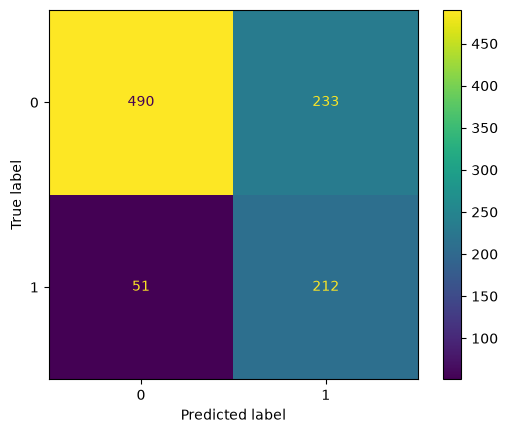

In [87]:
# After tuning
cm_lr = confusion_matrix(y_test, y_pred)
cm_disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr)
cm_disp_lr.plot()
plt.show()

In [88]:
# predict probabilities
y_pred_proba = model_lr.predict_proba(X_test)

# keep probabilities for the positive outcome only
y_pred_proba = y_pred_proba[:, 1]

# calculate pr-curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

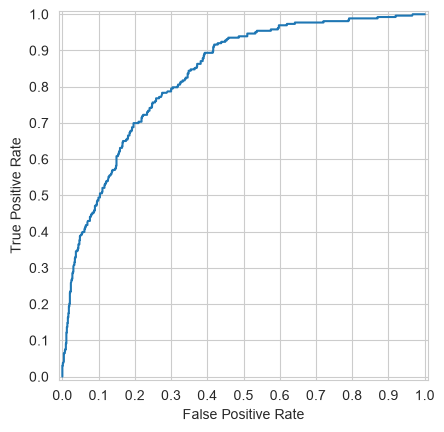

In [89]:
# ROC AUC curve
sns.set_style('whitegrid')
disp = RocCurveDisplay(fpr = fpr, tpr = tpr).plot()

list_num_lr = np.arange(0,1.1,0.1)
disp.ax_.set_xticks(list_num_lr)
disp.ax_.set_yticks(list_num_lr)
plt.show()

Kurva ROC diatas merupakan kurva yang menunjukkan trade-off antara proporsi churn yang terdeteksi (True Positive Rate) dan proporsi tidak churn yang salah dideteksi (False Positive Rate) di semua kemungkinan threshold dari 0-1.<br>
Selanjutnya, kita buat tabel hasil analisis threshold berbasis biaya bisnis untuk model `LogisticRegression` yang sudah didefinisikan pada bagian Business Understanding.

In [90]:
df_roc_curve_lr = pd.DataFrame({'fp_rate': fpr,
                                'tp_rate': tpr,
                                'thresholds': list(thresholds)
                                }).sort_values(['tp_rate', 'fp_rate'], ascending=[False,True])

# Jumlah tiap kelas di dataset
T_exit_lr = y_test[y_test==1].count()
F_exit_lr= y_test[y_test==0].count()                   

In [91]:
# Jumlah pelanggan tiap kelas
# Kelas True Positive, True Negative, True Negative, dan False Negative

df_roc_curve_lr['tp_cust'] = round(df_roc_curve_lr['tp_rate']*T_exit_lr,0)
df_roc_curve_lr['fn_cust'] = T_exit_lr - df_roc_curve_lr['tp_cust']
df_roc_curve_lr['tn_cust'] = round((1-df_roc_curve_lr['fp_rate'])*F_exit_lr,0)
df_roc_curve_lr['fp_cust'] = F_exit_lr - df_roc_curve_lr['tn_cust']

In [92]:
# Perhitungan cost kelas False Positive dan False Negative

df_roc_curve_lr['Cost_of_FP'] = df_roc_curve_lr['fp_cust']*100000
df_roc_curve_lr['Cost_of_FN'] = df_roc_curve_lr['fn_cust']*500000
df_roc_curve_lr['Total_Cost'] = df_roc_curve_lr['Cost_of_FN'] + df_roc_curve_lr['Cost_of_FP']

In [93]:
# Tabel threshold di atas default 0.50
df_roc_curve_lr[df_roc_curve_lr['thresholds']>0.50].sort_values(by='thresholds', ascending=True)

,fp_rate,tp_rate,thresholds,tp_cust,fn_cust,tn_cust,fp_cust,Cost_of_FP,Cost_of_FN,Total_Cost
220,0.319502,0.806084,0.502268,212.0,51.0,492.0,231.0,23100000.0,25500000.0,48600000.0
219,0.319502,0.802281,0.503118,211.0,52.0,492.0,231.0,23100000.0,26000000.0,49100000.0
218,0.318119,0.802281,0.505109,211.0,52.0,493.0,230.0,23000000.0,26000000.0,49000000.0
217,0.318119,0.798479,0.506027,210.0,53.0,493.0,230.0,23000000.0,26500000.0,49500000.0
216,0.313970,0.798479,0.508039,210.0,53.0,496.0,227.0,22700000.0,26500000.0,49200000.0
...,...,...,...,...,...,...,...,...,...,...
4,0.001383,0.038023,0.792601,10.0,253.0,722.0,1.0,100000.0,126500000.0,126600000.0
3,0.001383,0.030418,0.793186,8.0,255.0,722.0,1.0,100000.0,127500000.0,127600000.0
2,0.000000,0.030418,0.793310,8.0,255.0,723.0,0.0,0.0,127500000.0,127500000.0
1,0.000000,0.003802,0.796917,1.0,262.0,723.0,0.0,0.0,131000000.0,131000000.0


Tabel diatas menunjukkan bahwa semakin threshold naik, semakin naik biayanya. Dengan demikian, menaikkan threshold tidak menguntungkan.

In [94]:
# Tabel threshold dengan biaya terendah
df_roc_curve_lr[df_roc_curve_lr['tp_rate']<1].sort_values(by='Total_Cost', ascending=True)

,fp_rate,tp_rate,thresholds,tp_cust,fn_cust,tn_cust,fp_cust,Cost_of_FP,Cost_of_FN,Total_Cost
262,0.419087,0.916350,0.412188,241.0,22.0,420.0,303.0,30300000.0,11000000.0,41300000.0
264,0.428769,0.920152,0.398674,242.0,21.0,413.0,310.0,31000000.0,10500000.0,41500000.0
272,0.457815,0.935361,0.372754,246.0,17.0,392.0,331.0,33100000.0,8500000.0,41600000.0
266,0.438451,0.923954,0.391849,243.0,20.0,406.0,317.0,31700000.0,10000000.0,41700000.0
260,0.417704,0.912548,0.413179,240.0,23.0,421.0,302.0,30200000.0,11500000.0,41700000.0
...,...,...,...,...,...,...,...,...,...,...
5,0.002766,0.038023,0.792570,10.0,253.0,721.0,2.0,200000.0,126500000.0,126700000.0
2,0.000000,0.030418,0.793310,8.0,255.0,723.0,0.0,0.0,127500000.0,127500000.0
3,0.001383,0.030418,0.793186,8.0,255.0,722.0,1.0,100000.0,127500000.0,127600000.0
1,0.000000,0.003802,0.796917,1.0,262.0,723.0,0.0,0.0,131000000.0,131000000.0


Tabel diatas menunjukkan bahwa menurunkan threshold dapat menghemat biaya. Biaya yang dikeluarkan dengan threshold default (0.50) sekitar Rp 48,600,000. Di sisi lain, biaya terendah yang dikeluarkan bisa sebesar Rp 41,300,000 dengan threshold 0.41. Dengan demikian, threshold 0.41 aman dipilih untuk model `LogisticRegression`.

In [95]:
thr_lr = 0.41
y_proba = model_lr.predict_proba(X_test)[:, 1]
y_pred_thr = (y_proba >= thr_lr).astype(int)

print(classification_report(y_test, y_pred_thr))
print(confusion_matrix(y_test, y_pred_thr))
print('F2 :', fbeta_score(y_test, y_pred_thr, beta=2))
print('Recall :', recall_score(y_test, y_pred_thr))

              precision    recall  f1-score   support

           0       0.95      0.58      0.72       723
           1       0.44      0.92      0.60       263

    accuracy                           0.67       986
   macro avg       0.70      0.75      0.66       986
weighted avg       0.81      0.67      0.69       986

[[418 305]
 [ 22 241]]
F2 : 0.7540675844806007
Recall : 0.9163498098859315


Menurunkan threshold dari 0.50 menjadi 0.41 dapat menyelamatkan 29 pelanggan di kelas False Negative (sebelum 51, setelah 22) dan menambah 72 pelanggan di kelas False Positive (sebelum 233, setelah 305). Walaupun penambahan pelanggan di kelas False Positive lebih banyak dibandingkan dengan penurunan pelanggan di kelas False Negative, biaya total turun.

## **2. AdaBoostClassifier**

In [96]:
AdaBoostClassifier()

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None


In [97]:
?AdaBoostClassifier

Init signature:
AdaBoostClassifier(
    estimator=None,
    *,
    n_estimators=50,
    learning_rate=1.0,
    random_state=None,
)
Docstring:     
An AdaBoost classifier.

An AdaBoost [1]_ classifier is a meta-estimator that begins by fitting a
classifier on the original dataset and then fits additional copies of the
classifier on the same dataset but where the weights of incorrectly
classified instances are adjusted such that subsequent classifiers focus
more on difficult cases.

This class implements the algorithm based on [2]_.

Read more in the :ref:`User Guide <adaboost>`.

.. versionadded:: 0.14

Parameters
----------
estimator : object, default=None
    The base estimator from which the boosted ensemble is built.
    Support for sample weighting is required, as well as proper
    ``classes_`` and ``n_classes_`` attributes. If ``None``, then
    the base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`
    initialized with `max_depth=1`.

    .. versionadded:: 1.2
    

Pada bagian ini, kita akan coba lakukan hyperparameter tuning menggunakan model `AdaBoostClassifier` dengan transformer yang sudah dibinning dan metode resampling `RandomOverSampling`.<br>
<br>
Alasan pemilihan hyperparameter:
- `modeling__n_estimators` merupakan parameter pada model `AdaBoostClassifier` yang digunakan untuk menentukan *weak learners*. Pada bagian ini dipilih range(50,501,50) karena untuk melatih model dari nilai rendah hingga tinggi. Pada bagian ini digunakan untuk mencoba semua parameter dan menghasilkan model yang tidak underfitting dan overfitting.
- `modeling__learning_rate` merupakan parameter yang berfungsi untuk memperkecil atau memperbesar dampak dari setiap pohon pada model `AdaBoostClassifier`. Pada bagian ini dipilih [0.01, 0.05, 0.1, 0.5, 1.0] agar mencakup nilai learning rate rendah hingga tinggi sehingga pada proses tunning dapat melatih semua nilai learning rate.
- Pada bagian `modeling__estimator` dipilih max_depth 1, 2, dan 3 karena `AdaBoostClassifier` bekerja paling baik dengan weak learner. Pohon yang dangkal sangat cocok untuk `AdaBoostClassifier` karena jika terlalu dalam akan menyebabkan overfitting.
<br>

Metriks yang digunakan untuk tunning model `AdaBoostClassifier` sama dengan yang digunakan pada model `LogisticRegression`. Metriks yang digunakan pada proses tunning ada 4, yaitu  metriks F2 sebagai metriks penentu untuk menyeimbangkan recall dan precision sesuai biaya bisnis. Metriks recall, precision, dan average precision sebagai metriks pendamping. Tuning dioptimalkan dengan F2 karena cost FN lebih besar daripada cost FP. Tuning dioptimalkan dengan F2 ditandai dengan bagian `refit='f2'`. Recall dan precision digunakan untuk menjelaskan dibalik skor metriks F2 dan average precision digunakan untuk menilai kualitas sebelum threshold diatur.

In [98]:
# Model
mod_adaboost = AdaBoostClassifier(random_state=0)

# Define pipeline for Hyperparameter Tuning
pipe_prep_model_ab= Pipeline([
    ('preprocessing', transformer),
    ('resampling', ros),
    ('modeling', mod_adaboost)])

# Hyperparam
hyperparam_ab = {
    'modeling__n_estimators': range(50,501,50),
    'modeling__learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0],
    'modeling__estimator': [
        DecisionTreeClassifier(max_depth=1),
        DecisionTreeClassifier(max_depth=2),
        DecisionTreeClassifier(max_depth=3),
    ],
    'resampling': [smote, ros],
}

skfold = StratifiedKFold(n_splits=5)

f2 = make_scorer(fbeta_score, beta=2)
scoring = {
    'recall': 'recall',
    'precision': 'precision',
    'f2': f2,
    'avg_precision': 'average_precision',
}

# Method: Random search
gridsearch_ab = GridSearchCV(
    estimator = pipe_prep_model_ab,
    cv = skfold,
    n_jobs = -1,
    param_grid = hyperparam_ab,
    refit = 'f2',
    scoring = scoring,
    return_train_score=True,
    error_score='raise'
)

display(gridsearch_ab)

display(gridsearch_ab.fit(X_train, y_train))

print('Best score :', gridsearch_ab.best_score_)
print('Best params:', gridsearch_ab.best_params_)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=0))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'modeling__estimator': [DecisionTreeC...r(max_depth=1), DecisionTreeC...r(max_depth=2), ...], 'modeling__learning_rate': [0.01, 0.05, ...], 'modeling__n_estimators': range(50, 501, 50), 'resampling': [SMOTE(random_state=0), RandomOverSam...andom_state=0)]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'avg_precision': 'average_precision', 'f2': make_scorer(f...dict', beta=2), 'precision': 'precision', 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=F

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=0))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'modeling__estimator': [DecisionTreeC...r(max_depth=1), DecisionTreeC...r(max_depth=2), ...], 'modeling__learning_rate': [0.01, 0.05, ...], 'modeling__n_estimators': range(50, 501, 50), 'resampling': [SMOTE(random_state=0), RandomOverSam...andom_state=0)]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'avg_precision': 'average_precision', 'f2': make_scorer(f...dict', beta=2), 'precision': 'precision', 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=F

Best score : 0.7452526867906669
Best params: {'modeling__estimator': DecisionTreeClassifier(max_depth=2), 'modeling__learning_rate': 0.01, 'modeling__n_estimators': 350, 'resampling': SMOTE(random_state=0)}


Hyperparameter tunning pada model `AdaBoostClassifier` yang telah dilakukan menghasilkan best score dan best parameter sebagai berikut.
**Best score : 0.7452526867906669**<br>
Best score ini merupakan skor rata-rata F2 di cross validation untuk kombinasi yang terbaik.<br>
<br>
**Best parameternya adalah**
- modeling__estimator : DecisionTreeClassifier(max_depth=2)
- modeling__learning_rate  0.01,
- modeling__n_estimators: 350,
- resampling : SMOTE(random_state=0)

In [99]:
# Define model after tuning
model_ab = gridsearch_ab.best_estimator_

# fit
model_ab.fit(X_train, y_train)

# predict
y_pred = model_ab.predict(X_test)
proba_test = model_ab.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print('F2 :', fbeta_score(y_test, y_pred, beta=2))
print('Average Precision :', average_precision_score(y_test, proba_test))


print('F bscore train: ', fbeta_score(y_train, model_ab.predict(X_train), beta=2) )
print('F bscore test: ', fbeta_score(y_test, y_pred, beta=2) )
print('Recall score: ', recall_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.62      0.74       723
           1       0.45      0.85      0.59       263

    accuracy                           0.68       986
   macro avg       0.69      0.74      0.67       986
weighted avg       0.80      0.68      0.70       986

[[451 272]
 [ 39 224]]
F2 : 0.7235142118863049
Average Precision : 0.6357844570372614
F bscore train:  0.7446468520294024
F bscore test:  0.7235142118863049
Recall score:  0.8517110266159695


Dari hasil diatas diperoleh bahwa
- Kelas 1 (Pelanggan yang Churn): skor metriks precision sebesar 0.45, recall sebesar 0.85, dan F1 sebesar 0.59
- Kelas 0 (Pelanggan yang tidak Churn): skor metriks precision sebesar 0.92, recall sebesar 0.62, dan F1 sebesar 0.74
- Skor metriks utama F2 sebesar 0.723 dan recall 0.851 di threshold default
- F2 train sebesar 0.744 dan F2 test sebesar 0.723 sehingga model tidak overfit

In [100]:
# Column/Features name after transformed; access to pipeline
feature_name_ab = gridsearch_ab.best_estimator_[-3].get_feature_names_out().tolist()

# Feature importance; access to pipeline
feature_imp_ab = gridsearch_ab.best_estimator_[-1].feature_importances_

df_feature_imp_ab = pd.DataFrame(
    {'Feature name' : feature_name_ab,
    'Feature importance' : feature_imp_ab}
)

df_feature_imp_ab.sort_values(by='Feature importance', ascending=False)

,Feature name,Feature importance
12,onehot__Contract_Two year,0.639670
11,onehot__Contract_One year,0.130682
15,scaler_discrete__tenure,0.077629
5,onehot__InternetService_Fiber optic,0.057639
14,scaler_continuous__MonthlyCharges,0.046197
9,onehot__TechSupport_No internet service,0.010415
13,onehot__PaperlessBilling_Yes,0.008659
3,onehot__OnlineBackup_No internet service,0.007153
6,onehot__InternetService_No,0.005986
7,onehot__DeviceProtection_No internet service,0.005690


Daftar feature importance diatas, diperoleh bahwa ada beberapa feature yang bernilai 0. Feature tersebut tetap masuk dan dihitung pada model, namun tidak dipakai atau diabaikan. Feature tersebut adalah onehot__OnlineBackup_Yes, onehot__Dependents_Yes, onehot__TechSupport_Yes, dan onehot__DeviceProtection_Yes.

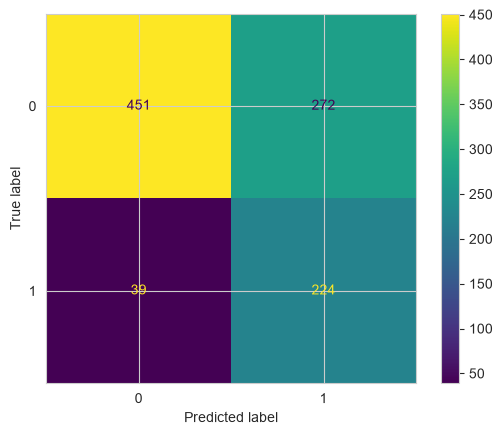

In [101]:
# After tuning
cm_ab = confusion_matrix(y_test, y_pred)
cm_disp_ab = ConfusionMatrixDisplay(confusion_matrix=cm_ab)
cm_disp_ab.plot()
plt.show()

In [102]:
# predict probabilities
y_pred_proba = model_ab.predict_proba(X_test)

# keep probabilities for the positive outcome only
y_pred_proba = y_pred_proba[:, 1]

# calculate pr-curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

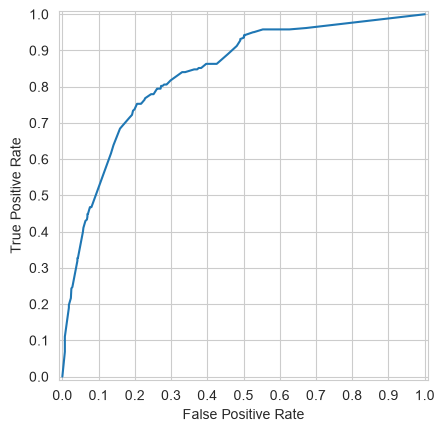

In [104]:
# ROC AUC curve
sns.set_style('whitegrid')
disp = RocCurveDisplay(fpr = fpr, tpr = tpr).plot()

list_num_ab = np.arange(0,1.1,0.1)
disp.ax_.set_xticks(list_num_ab)
disp.ax_.set_yticks(list_num_ab)
plt.show()

Kurva ROC diatas merupakan kurva yang menunjukkan trade-off antara proporsi churn yang terdeteksi (True Positive Rate) dan proporsi tidak churn yang salah dideteksi (False Positive Rate) di semua kemungkinan threshold dari 0-1.<br>
Selanjutnya, kita buat tabel hasil analisis threshold berbasis biaya bisnis untuk model `AdaBoostClassifier` yang sudah didefinisikan pada bagian Business Understanding.

In [105]:
df_roc_curve_ab = pd.DataFrame({'fp_rate': fpr,
                                'tp_rate': tpr,
                                'thresholds': list(thresholds)
                                }).sort_values(['tp_rate', 'fp_rate'], ascending=[False,True])

# Jumlah tiap kelas di dataset
T_exit_ab = y_test[y_test==1].count()
F_exit_ab= y_test[y_test==0].count()                   

In [106]:
# Jumlah pelanggan tiap kelas
# Kelas True Positive, True Negative, True Negative, dan False Negative

df_roc_curve_ab['tp_cust'] = round(df_roc_curve_ab['tp_rate']*T_exit_ab,0)
df_roc_curve_ab['fn_cust'] = T_exit_ab - df_roc_curve_ab['tp_cust']
df_roc_curve_ab['tn_cust'] = round((1-df_roc_curve_ab['fp_rate'])*F_exit_ab,0)
df_roc_curve_ab['fp_cust'] = F_exit_ab - df_roc_curve_ab['tn_cust']

In [107]:
# Perhitungan cost kelas False Positive dan False Negative

df_roc_curve_ab['Cost_of_FP'] = df_roc_curve_ab['fp_cust']*100000
df_roc_curve_ab['Cost_of_FN'] = df_roc_curve_ab['fn_cust']*500000
df_roc_curve_ab['Total_Cost'] = df_roc_curve_ab['Cost_of_FN'] + df_roc_curve_ab['Cost_of_FP']

In [108]:
# Tabel threshold di atas default 0.50
df_roc_curve_ab[df_roc_curve_ab['thresholds']>0.50].sort_values(by='thresholds', ascending=True)

,fp_rate,tp_rate,thresholds,tp_cust,fn_cust,tn_cust,fp_cust,Cost_of_FP,Cost_of_FN,Total_Cost
50,0.376210,0.851711,0.501922,224.0,39.0,451.0,272.0,27200000.0,19500000.0,46700000.0
49,0.372061,0.847909,0.502277,223.0,40.0,454.0,269.0,26900000.0,20000000.0,46900000.0
48,0.363762,0.847909,0.517361,223.0,40.0,460.0,263.0,26300000.0,20000000.0,46300000.0
47,0.338866,0.840304,0.518260,221.0,42.0,478.0,245.0,24500000.0,21000000.0,45500000.0
46,0.336100,0.840304,0.530840,221.0,42.0,480.0,243.0,24300000.0,21000000.0,45300000.0
45,0.330567,0.840304,0.535684,221.0,42.0,484.0,239.0,23900000.0,21000000.0,44900000.0
44,0.298755,0.817490,0.544551,215.0,48.0,507.0,216.0,21600000.0,24000000.0,45600000.0
43,0.287690,0.806084,0.551552,212.0,51.0,515.0,208.0,20800000.0,25500000.0,46300000.0
42,0.286307,0.806084,0.577507,212.0,51.0,516.0,207.0,20700000.0,25500000.0,46200000.0
41,0.280775,0.806084,0.596783,212.0,51.0,520.0,203.0,20300000.0,25500000.0,45800000.0


Tabel diatas menunjukkan saat threshold naik dari 0.50 ke 0.53, biaya total turun. Namun, threshold di atas 0.53, semakin naik thresholdnya, biaya totalnya cenderung naik.

In [109]:
# Tabel threshold dengan biaya terendah
df_roc_curve_ab[df_roc_curve_ab['tp_rate']<1].sort_values(by='Total_Cost', ascending=True)

,fp_rate,tp_rate,thresholds,tp_cust,fn_cust,tn_cust,fp_cust,Cost_of_FP,Cost_of_FN,Total_Cost
65,0.502075,0.942966,0.264004,248.0,15.0,360.0,363.0,36300000.0,7500000.0,43800000.0
66,0.504841,0.942966,0.248843,248.0,15.0,358.0,365.0,36500000.0,7500000.0,44000000.0
63,0.500692,0.939163,0.299628,247.0,16.0,361.0,362.0,36200000.0,8000000.0,44200000.0
64,0.502075,0.939163,0.272308,247.0,16.0,360.0,363.0,36300000.0,8000000.0,44300000.0
61,0.491010,0.931559,0.333558,245.0,18.0,368.0,355.0,35500000.0,9000000.0,44500000.0
...,...,...,...,...,...,...,...,...,...,...
4,0.017981,0.197719,0.819218,52.0,211.0,710.0,13.0,1300000.0,105500000.0,106800000.0
3,0.017981,0.190114,0.829850,50.0,213.0,710.0,13.0,1300000.0,106500000.0,107800000.0
2,0.006916,0.110266,0.866010,29.0,234.0,718.0,5.0,500000.0,117000000.0,117500000.0
1,0.006916,0.068441,0.880797,18.0,245.0,718.0,5.0,500000.0,122500000.0,123000000.0


Tabel diatas menunjukkan bahwa menurunkan threshold dapat menghemat biaya. Biaya yang dikeluarkan dengan threshold default (0.50) sekitar Rp 46,700,000. Di sisi lain, biaya terendah yang dikeluarkan bisa sebesar Rp 43,800,000 dengan threshold 0.26. Dengan demikian, threshold 0.26 aman dipilih untuk model `AdaBoostClassifier`.

In [110]:
thr_ab = 0.26
y_proba = model_ab.predict_proba(X_test)[:, 1]
y_pred_thr = (y_proba >= thr_ab).astype(int)

print(classification_report(y_test, y_pred_thr))
print(confusion_matrix(y_test, y_pred_thr))
print('F2 :', fbeta_score(y_test, y_pred_thr, beta=2))
print('Recall :', recall_score(y_test, y_pred_thr))

              precision    recall  f1-score   support

           0       0.96      0.50      0.66       723
           1       0.41      0.94      0.57       263

    accuracy                           0.62       986
   macro avg       0.68      0.72      0.61       986
weighted avg       0.81      0.62      0.63       986

[[360 363]
 [ 15 248]]
F2 : 0.745640408899579
Recall : 0.9429657794676806


Menurunkan threshold dari 0.50 menjadi 0.26 dapat menyelamatkan 24 pelanggan di kelas False Negative (sebelum 39, setelah 15) dan menambah 91 pelanggan di kelas False Positive (sebelum 272, setelah 363). Walaupun penambahan pelanggan di kelas False Positive lebih banyak dibandingkan dengan penurunan pelanggan di kelas False Negative, biaya total turun.

# **Selecting Final Model**

Dari percobaan hyperparameter tuning model `LogisticRegression` dan `AdaBoostClassifier` diatas diperoleh bahwa:
- Biaya total terkecil untuk model `LogisticRegression` adalah Rp 41,300,000 dengan threshold 0.41
- Biaya total terkecil untuk model `AdaBoostClassifier` adalah Rp 43,800,000 dengan threshold 0.26
<br>

Dari hasil tersebut, model final yang dipilih adalah model `LogisticRegression`. Selanjutnya, kita akan coba lakukan model-based feature selection pada model terbaik `LogisticRegression` yang terpilih.

In [113]:
from sklearn.base import clone
from sklearn.feature_selection import SelectFromModel
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_score
from imblearn.pipeline import Pipeline

In [114]:
print(f'Skor dengan feature awal: {gridsearch_lr.best_score_:.4f}')

for batas in [1e-5, 0.01, 0.05, 0.1, 0.2]:
    best_model = gridsearch_lr.best_estimator_
    all_names = best_model.named_steps['preprocessing'].get_feature_names_out().tolist()
    
    drop = df_coef_lr.loc[df_coef_lr['Abs coefficient'] <= batas, 'Feature name'].tolist()
    keep_idx = [i for i, nama in enumerate(all_names) if nama not in drop]
    
    steps = [(nama, clone(step)) for nama, step in best_model.steps]
    steps.insert(1, ('dropper', ColumnTransformer([('keep', 'passthrough', keep_idx)])))
    pipe_batas = Pipeline(steps)
    
    skor = cross_val_score(pipe_batas,
                           X_train,
                           y_train,
                           cv=gridsearch_lr.cv,
                           scoring=f2,
                           error_score='raise')

    print(f'Batas {batas} | dibuang {len(drop)} | sisa {len(keep_idx)} | F2 CV: {skor.mean():.4f} | Skor std: {skor.std():.4f}')


Skor dengan feature awal: 0.7372
Batas 1e-05 | dibuang 4 | sisa 14 | F2 CV: 0.7372 | Skor std: 0.0081
Batas 0.01 | dibuang 8 | sisa 10 | F2 CV: 0.7372 | Skor std: 0.0081
Batas 0.05 | dibuang 8 | sisa 10 | F2 CV: 0.7372 | Skor std: 0.0081
Batas 0.1 | dibuang 10 | sisa 8 | F2 CV: 0.7347 | Skor std: 0.0045
Batas 0.2 | dibuang 10 | sisa 8 | F2 CV: 0.7347 | Skor std: 0.0045


Dari hasil diatas diperoleh bahwa dengan menghapus feature yang nilai koefisiennya dibawah 0.05, skor F2 dan standar deviasinya masih sama. Dengan demikian, kita hapus 8 feature yang koefisiennya dibawah 0.05.

In [116]:
best_model = gridsearch_lr.best_estimator_
all_names = best_model.named_steps['preprocessing'].get_feature_names_out().tolist()
    
drop = df_coef_lr.loc[df_coef_lr['Abs coefficient'] <= 0.05, 'Feature name'].tolist()
keep_idx = [i for i, nama in enumerate(all_names) if nama not in drop]
    
steps = [(nama, clone(step)) for nama, step in best_model.steps]
steps.insert(1, ('dropper', ColumnTransformer([('keep', 'passthrough', keep_idx)])))
pipe_batas = Pipeline(steps)

pipe_batas

,steps,"[('preprocessing', ...), ('dropper', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehot', ...), ('scaler_continuous', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it mu

In [ ]:
pipe_batas.fit(X_train, y_train)

print(pipe_batas.named_steps['modeling'].coef_.shape)
print([all_names[i] for i in keep_idx])   

(1, 10)
['onehot__Dependents_Yes', 'onehot__OnlineSecurity_Yes', 'onehot__OnlineBackup_Yes', 'onehot__InternetService_Fiber optic', 'onehot__TechSupport_No internet service', 'onehot__Contract_One year', 'onehot__Contract_Two year', 'scaler_continuous__MonthlyCharges', 'bin_or_scale__tenure_0.0', 'bin_or_scale__tenure_2.0']


Berikut list feature yang dipertahankan pada model final `LogisticRegression`:
1. 'onehot__Dependents_Yes'
2. 'onehot__OnlineSecurity_Yes'
3. 'onehot__OnlineBackup_Yes'
4. 'onehot__InternetService_Fiber optic'
5. 'onehot__TechSupport_No internet service'
6. 'onehot__Contract_One year'
7. 'onehot__Contract_Two year'
8. 'scaler_continuous__MonthlyCharges'
9. 'bin_or_scale__tenure_0.0'
10. 'bin_or_scale__tenure_2.0'

In [118]:
# predict
y_pred = pipe_batas.predict(X_test)
proba_test = pipe_batas.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print('F2 :', fbeta_score(y_test, y_pred, beta=2))
print('Average Precision :', average_precision_score(y_test, proba_test))
print('F bscore train: ', fbeta_score(y_train, pipe_batas.predict(X_train), beta=2) )
print('F bscore test: ', fbeta_score(y_test, y_pred, beta=2) )
print('Recall score: ', recall_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.68      0.78       723
           1       0.48      0.81      0.60       263

    accuracy                           0.71       986
   macro avg       0.69      0.74      0.69       986
weighted avg       0.79      0.71      0.73       986

[[490 233]
 [ 51 212]]
F2 : 0.7080828323313293
Average Precision : 0.6422257257451421
F bscore train:  0.7344213649851632
F bscore test:  0.7080828323313293
Recall score:  0.8060836501901141


Dari hasil diatas diperoleh bahwa
- Kelas 1 (Pelanggan yang Churn): skor metriks precision sebesar 0.48, recall sebesar 0.81, dan F1 sebesar 0.60
- Kelas 0 (Pelanggan yang tidak Churn): skor metriks precision sebesar 0.91, recall sebesar 0.68, dan F1 sebesar 0.78
- Skor metriks utama F2 sebesar 0.708 dan recall 0.806 di threshold default
- F2 train sebesar 0.734 dan F2 test sebesar 0.708 sehingga model tidak overfit

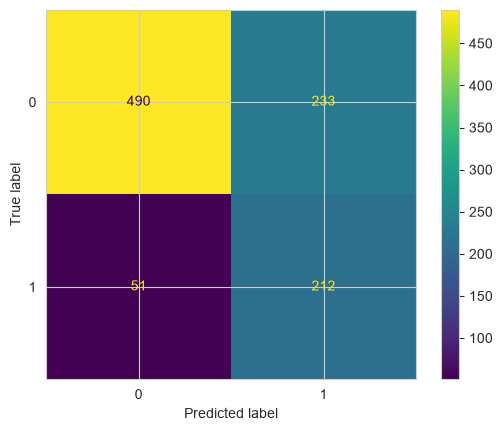

In [119]:
# After tuning
cm_lr = confusion_matrix(y_test, y_pred)
cm_disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr)
cm_disp_lr.plot()
plt.show()

In [120]:
# predict probabilities
y_pred_proba = pipe_batas.predict_proba(X_test)

# keep probabilities for the positive outcome only
y_pred_proba = y_pred_proba[:, 1]

# calculate pr-curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

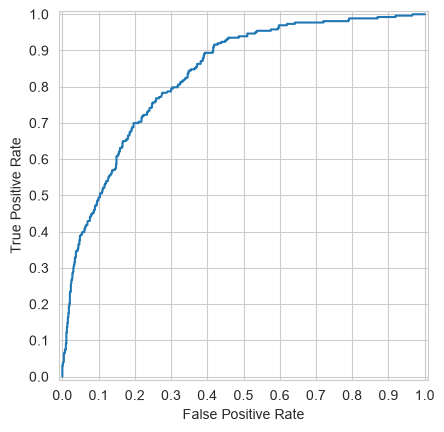

In [121]:
# ROC AUC curve
sns.set_style('whitegrid')
disp = RocCurveDisplay(fpr = fpr, tpr = tpr).plot()

list_num_lr = np.arange(0,1.1,0.1)
disp.ax_.set_xticks(list_num_lr)
disp.ax_.set_yticks(list_num_lr)
plt.show()

Kurva ROC diatas merupakan kurva yang menunjukkan trade-off antara proporsi churn yang terdeteksi (True Positive Rate) dan proporsi tidak churn yang salah dideteksi (False Positive Rate) di semua kemungkinan threshold dari 0-1.<br>
Selanjutnya, kita buat tabel hasil analisis threshold berbasis biaya bisnis untuk model `LogisticRegression` yang sudah didefinisikan pada bagian Business Understanding.

In [122]:
df_roc_curve_lr = pd.DataFrame({'fp_rate': fpr,
                                'tp_rate': tpr,
                                'thresholds': list(thresholds)
                                }).sort_values(['tp_rate', 'fp_rate'], ascending=[False,True])

# Jumlah tiap kelas di dataset
T_exit_lr = y_test[y_test==1].count()
F_exit_lr= y_test[y_test==0].count()                   

In [123]:
# Jumlah pelanggan tiap kelas
# Kelas True Positive, True Negative, True Negative, dan False Negative

df_roc_curve_lr['tp_cust'] = round(df_roc_curve_lr['tp_rate']*T_exit_lr,0)
df_roc_curve_lr['fn_cust'] = T_exit_lr - df_roc_curve_lr['tp_cust']
df_roc_curve_lr['tn_cust'] = round((1-df_roc_curve_lr['fp_rate'])*F_exit_lr,0)
df_roc_curve_lr['fp_cust'] = F_exit_lr - df_roc_curve_lr['tn_cust']

In [124]:
# Perhitungan cost kelas False Positive dan False Negative

df_roc_curve_lr['Cost_of_FP'] = df_roc_curve_lr['fp_cust']*100000
df_roc_curve_lr['Cost_of_FN'] = df_roc_curve_lr['fn_cust']*500000
df_roc_curve_lr['Total_Cost'] = df_roc_curve_lr['Cost_of_FN'] + df_roc_curve_lr['Cost_of_FP']

In [125]:
# Tabel threshold di atas default 0.50
df_roc_curve_lr[df_roc_curve_lr['thresholds']>0.50].sort_values(by='thresholds', ascending=True)

,fp_rate,tp_rate,thresholds,tp_cust,fn_cust,tn_cust,fp_cust,Cost_of_FP,Cost_of_FN,Total_Cost
220,0.319502,0.806084,0.502232,212.0,51.0,492.0,231.0,23100000.0,25500000.0,48600000.0
219,0.319502,0.802281,0.503215,211.0,52.0,492.0,231.0,23100000.0,26000000.0,49100000.0
218,0.318119,0.802281,0.504998,211.0,52.0,493.0,230.0,23000000.0,26000000.0,49000000.0
217,0.318119,0.798479,0.506107,210.0,53.0,493.0,230.0,23000000.0,26500000.0,49500000.0
216,0.313970,0.798479,0.507996,210.0,53.0,496.0,227.0,22700000.0,26500000.0,49200000.0
...,...,...,...,...,...,...,...,...,...,...
4,0.001383,0.038023,0.792562,10.0,253.0,722.0,1.0,100000.0,126500000.0,126600000.0
3,0.001383,0.030418,0.793144,8.0,255.0,722.0,1.0,100000.0,127500000.0,127600000.0
2,0.000000,0.030418,0.793267,8.0,255.0,723.0,0.0,0.0,127500000.0,127500000.0
1,0.000000,0.003802,0.796854,1.0,262.0,723.0,0.0,0.0,131000000.0,131000000.0


Tabel diatas menunjukkan bahwa semakin threshold naik, semakin naik biayanya. Dengan demikian, menaikkan threshold tidak menguntungkan.

In [126]:
# Tabel threshold dengan biaya terendah
df_roc_curve_lr[df_roc_curve_lr['tp_rate']<1].sort_values(by='Total_Cost', ascending=True)

,fp_rate,tp_rate,thresholds,tp_cust,fn_cust,tn_cust,fp_cust,Cost_of_FP,Cost_of_FN,Total_Cost
261,0.419087,0.916350,0.412198,241.0,22.0,420.0,303.0,30300000.0,11000000.0,41300000.0
263,0.428769,0.920152,0.398757,242.0,21.0,413.0,310.0,31000000.0,10500000.0,41500000.0
271,0.457815,0.935361,0.372695,246.0,17.0,392.0,331.0,33100000.0,8500000.0,41600000.0
265,0.438451,0.923954,0.391842,243.0,20.0,406.0,317.0,31700000.0,10000000.0,41700000.0
259,0.417704,0.912548,0.413379,240.0,23.0,421.0,302.0,30200000.0,11500000.0,41700000.0
...,...,...,...,...,...,...,...,...,...,...
5,0.002766,0.038023,0.792532,10.0,253.0,721.0,2.0,200000.0,126500000.0,126700000.0
2,0.000000,0.030418,0.793267,8.0,255.0,723.0,0.0,0.0,127500000.0,127500000.0
3,0.001383,0.030418,0.793144,8.0,255.0,722.0,1.0,100000.0,127500000.0,127600000.0
1,0.000000,0.003802,0.796854,1.0,262.0,723.0,0.0,0.0,131000000.0,131000000.0


Tabel diatas menunjukkan bahwa menurunkan threshold dapat menghemat biaya. Biaya yang dikeluarkan dengan threshold default (0.50) sekitar Rp 48,600,000. Di sisi lain, biaya terendah yang dikeluarkan bisa sebesar Rp 41,300,000 dengan threshold 0.41. Dengan demikian, threshold 0.41 aman dipilih untuk model `LogisticRegression`.

In [ ]:
thr = 0.41
y_proba = pipe_batas.predict_proba(X_test)[:, 1]
y_pred_thr = (y_proba >= thr).astype(int)

print(classification_report(y_test, y_pred_thr))
print(confusion_matrix(y_test, y_pred_thr))
print('F2 :', fbeta_score(y_test, y_pred_thr, beta=2))
print('Recall :', recall_score(y_test, y_pred_thr))

              precision    recall  f1-score   support

           0       0.95      0.58      0.72       723
           1       0.44      0.92      0.60       263

    accuracy                           0.67       986
   macro avg       0.70      0.75      0.66       986
weighted avg       0.81      0.67      0.69       986

[[418 305]
 [ 22 241]]
F2 : 0.7540675844806007
Recall : 0.9163498098859315


# **Selected Model**

In [127]:
best_model_final = pipe_batas.fit(X_train, y_train)
best_model_final

,steps,"[('preprocessing', ...), ('dropper', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](10,)","['Dependents','tenure','OnlineSecurity',...,'Contract','PaperlessBilling', 'MonthlyCharges']"
n_features_in_,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehot', ...), ('scaler_continuous', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [128]:
feature_name_lr_final = [all_names[i] for i in keep_idx]

coef_lr_final = pipe_batas[-1].coef_[0]

df_coef_lr_final = pd.DataFrame(
    {'Feature name' : feature_name_lr_final,
    'Coefficient': coef_lr_final,
    'Odds ratio': np.exp(coef_lr_final),
    'Abs coefficient': np.abs(coef_lr_final)}
)

df_coef_lr_final.sort_values(by='Abs coefficient', ascending=False)

,Feature name,Coefficient,Odds ratio,Abs coefficient
6,onehot__Contract_Two year,-1.255201,0.285018,1.255201
8,bin_or_scale__tenure_0.0,0.654716,1.924595,0.654716
5,onehot__Contract_One year,-0.633697,0.530626,0.633697
3,onehot__InternetService_Fiber optic,0.593845,1.810938,0.593845
4,onehot__TechSupport_No internet service,-0.347098,0.706736,0.347098
9,bin_or_scale__tenure_2.0,-0.333021,0.716755,0.333021
1,onehot__OnlineSecurity_Yes,-0.202540,0.816653,0.202540
7,scaler_continuous__MonthlyCharges,0.201200,1.222869,0.201200
2,onehot__OnlineBackup_Yes,-0.094039,0.910247,0.094039
0,onehot__Dependents_Yes,-0.085252,0.918281,0.085252


# **Logistic Regression Explanation**

1. Logistic Regression Formula:

$$P = \frac{e^{\alpha+\beta X}}{1+e^{\alpha+\beta X}}$$
keterangan:<br>
$P$ :probabilitas pelanggan churn<br>
$\alpha$ : intersep atau konstanta model<br>
$\beta X$ : jumlah koefisien tiap feature yang dikalikan dengan nilainya<br>
<br>
2. Model Final LogisticRegression memiliki 10 feature. Misalkan kita ambil 4 feature, yaitu<br>
`Intercept` = $\alpha$,<br>
`onehot__Contract_Two year` = -1.255201,<br>
`bin_or_scale__tenure_0.0` = 0.654716,<br>
`onehot__Contract_One year` = -0.633697.<br>

Maka, formula LogisticRegression menjadi
<br>

$$P = \frac{e^{\alpha-1.255201X_{\text{onehot\_\_Contract\_TwoYear}}+0.654716X_{\text{bin\_or\_scale\_\_tenure\_0.0}}-0.633697X_{\text{onehot\_\_Contract\_OneYear}}+\dots+\beta X}}{1+e^{\alpha-1.255201X_{\text{onehot\_\_Contract\_TwoYear}}+0.654716X_{\text{bin\_or\_scale\_\_tenure\_0.0}}-0.633697X_{\text{onehot\_\_Contract\_OneYear}}+\dots+\beta X}}$$

3. Tafsiran koefisien feature pada model final sebagai berikut:

| Feature Name | Odds ratio | Deskripsi |
| --- | --- | --- |
| onehot__Contract_Two year | 0.285018 | Feature ini dibandingkan Contract_Month-to-month, odds churn 72% lebih rendah |
| bin_or_scale__tenure_0.0 | 1.924595 | Pelanggan di kelompok tenure paling pendek memiliki odds churn 92% lebih tinggi dibandingkan dengan pelanggan di kelompok tenure tengah |
| onehot__Contract_One year | 0.530626| Feature ini dibandingkan Contract_Month-to-month, odds churn 47% lebih rendah |
| onehot__InternetService_Fiber optic | 1.810938 | Feature ini dibandingkan InternetService_DSL, odds churn 81% lebih tinggi |
| onehot__TechSupport_No internet service | 0.706736| Pelanggan tanpa layanan internet memiliki odds chrun 28% lebih rendah. Feature ini identik dengan kelompok No internet service lainnya sehingga feature ini dapat mewakili semua kelompok pelanggan tanpa internet lainnya (No internet service) |
| bin_or_scale__tenure_2.0 | 0.716755 | Pelanggan di kelompok tenure paling panjang memiliki odds churn 28% lebih rendah dibandingkan dengan pelanggan di kelompok tenure tengah |
| onehot__OnlineSecurity_Yes | 0.816653 | Pelanggan di kelompok yang menggunakan Online Security memiliki odds churn 18% lebih rendah dibandingkan pelanggan di kelompok yang tidak menggunakan Online Security |
| scaler_continuous__MonthlyCharges | 1.222869 | Setiap kenaikan 1 unit MonthlyCharges (setelah dilakukan scaling menggunakan Robust Scaler), odds churn naik 22% |
| onehot__OnlineBackup_Yes | 0.910247 | Pelanggan di kelompok yang menggunakan Online Backup memiliki odds churn 9% lebih rendah dibandingkan pelanggan di kelompok yang tidak menggunakan Online Backup |
| onehot__Dependents_Yes | 0.918281 | Pelanggan di kelompok yang masih ada tanggungan memiliki odds churn 8% lebih rendah dibandingkan dengan pelanggan di kelompok yang tidak ada tanggungan |

# **Shapley Value of Explanations (SHAP)**

In [129]:
import shap

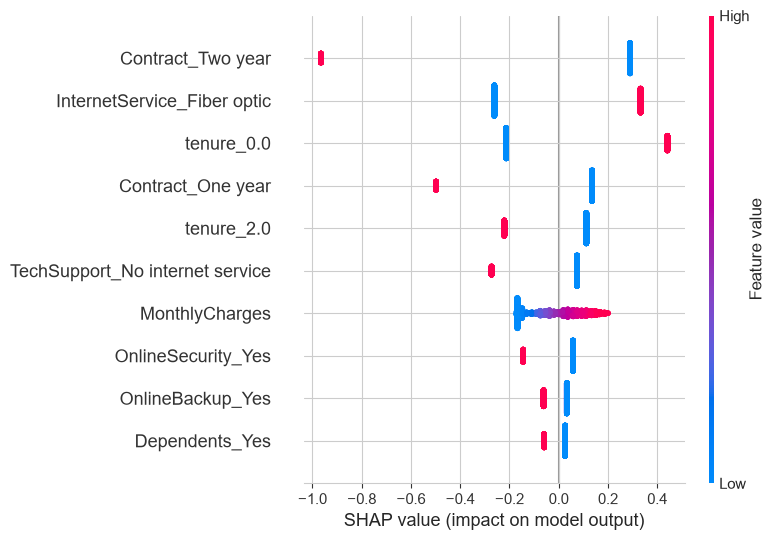

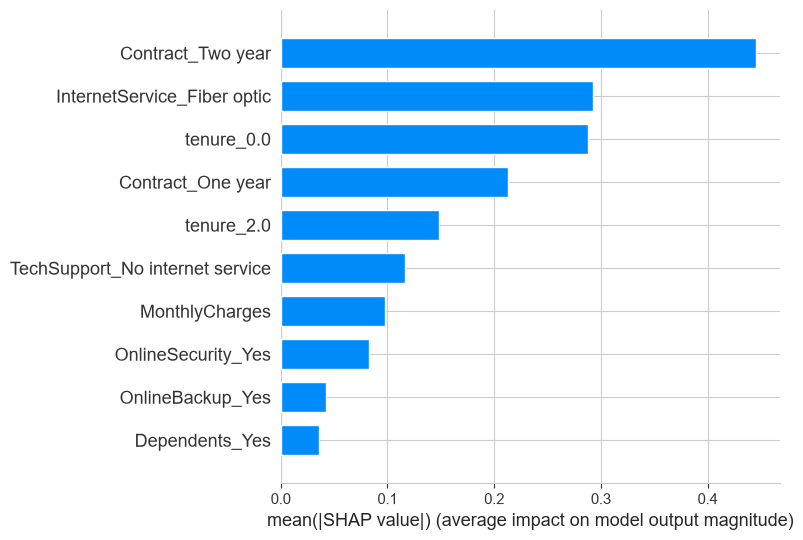

In [130]:
# define model final
model_final = pipe_batas[-1]
nama = [all_names[i].split('__', 1)[1] for i in keep_idx]

# Data yang masuk ke model
data_train = pd.DataFrame(pipe_batas[:2].transform(X_train),
                          columns=nama)

# agar dapat memakai semua X train
masker = shap.maskers.Independent(data_train, max_samples=len(data_train))

# define explainer
explainer = shap.LinearExplainer(model_final, masker)

# hitung shap value untuk tiap baris di data train
shap_train = explainer.shap_values(data_train)

# tampilkan dalam bentuk plot
shap.summary_plot(shap_train, data_train)

shap.summary_plot(shap_train, data_train, plot_type='bar')

Plot SHAP diatas menunjukkan feature-feature terpilih dan pengaruhnya terhadap churn atau tidaknya seorang pelanggan.
- Sumbu X merupakan kontribusi feature ke log-odds churn. Semakin positif nilainya, maka hasilnya menuju ke arah churn. Semakin negatif nilainya, maka hasilnya menuju ke arah tidak churn
- Warna pada plot menunjukan nilai feature. Warna merah menandakan nilai featurenya tinggi (1) dan warna biru menandakan nilai featurenya rendah (0).
<br>

| Feature | Feature Value | Deskripsi |
| --- | --- | --- |
| Contract_Two year | Warna merah di sekitar -0.90, sedangkan warna biru di sekitar +0.30 | Kontrak selama 2 tahun sangat menurunkan risiko pelanggan untuk churn |
| InternetService_Fiber optic | Warna merah di sekitar +0.35, sedangkan warna biru di sekitar -0.25 | Penggunaa Internet Service jenis Fiber Optic menaikkan risiko pelanggan untuk churn |
| tenure_0.0 | Warna merah di sekitar +0.45, sedangkan warna biru di sekitar -0.20 | Kelompok tenure paling pendek menaikkan risiko pelanggan untuk churn |
| Contract_One year | Warna merah di sekitar -0.50, sedangkan warna biru di sekitar +0.10 | Kontrak selama 1 tahun sangat menurunkan risiko pelanggan untuk churn |
| tenure_2.0| Warna merah di sekitar -0.20, sedangkan warna biru di sekitar +0.10 | Kelompok tenure paling panjang menurunkan risiko pelanggan untuk churn |
| TechSupport_No internet service | Warna merah di sekitar -0.25, sedangkan warna biru di sekitar +0.10 | Kelompok tanpa internet menurunkan risiko pelanggan untuk churn |
| MonthlyCharges | Warna menyebar pada rentang -0.20 hingga +0.20 dengan warna merah di sisi paling kanan dan warna biru di sisi paling kiri | Pengaruh MonthCharges kecil dan linear  |
| OnlineSecurity_Yes | Warna merah di sekitar -0.15, sedangkan warna biru di sekitar +0.05 | Pengaruh kelompok yang memiliki Online Security kecil dan menurunkan risiko pelanggan untuk churn |
| OnlineBackup_Yes | Warna merah di sekitar -0.10, sedangkan warna biru di sekitar +0.05 | Pengaruh kelompok yang memiliki Online Backup kecil dan menurunkan risiko pelanggan untuk churn |
| Dependents_Yes | Warna merah di sekitar -0.10, sedangkan warna biru di sekitar +0.05 | Pengaruh kelompok yang memiliki tagihan dan menurunkan risiko pelanggan untuk churn |


Berdasarkan plot SHAP diatas diperoleh faktor-faktor yang memengaruhi prediksi pelanggan untuk churn sebagai berikut.
- Jenis kontrak layanan : kontrak tahunan (1 dan 2 tahun) menurunkan risiko pelanggan untuk churn
- Jenis internet service : layanan Fiber Optic menaikkan risiko pelanggan untuk churn
- Tenure : tenure paling pendek menaikkan risiko pelanggan untuk churn, tenure paling panjang menurunkan risiko pelanggan untuk churn
- OnlineSecurity_Yes, OnlineBackup_Yes, Dependents_Yes memiliki pengaruh yang kecil terhadap prediksi pelanggan untuk churn.


**Test Data at index 0**

In [131]:
X_test.iloc[[0]]

,Dependents,tenure,OnlineSecurity,OnlineBackup,InternetService,DeviceProtection,TechSupport,Contract,PaperlessBilling,MonthlyCharges
1654,Yes,62,Yes,Yes,Fiber optic,Yes,Yes,Two year,No,115.55


In [132]:
shap.initjs()

# Bandingkan dengan hasil asli
print(f"Hasil prediksi untuk pelanggan ini adalah: {('Churn' if y_test.iloc[0] == 1 else 'Tidak Churn')} from y_test")
# Data yang masuk ke model
data_test = pd.DataFrame(pipe_batas[:2].transform(X_test),
                          columns=nama)

# hitung shap value untuk tiap baris di data test
shap_test = explainer.shap_values(data_test)

# tampilkan dalam bentuk plot
shap.force_plot(explainer.expected_value, shap_test[0], data_test.iloc[0])

Hasil prediksi untuk pelanggan ini adalah: Tidak Churn from y_test


In [133]:
# Batas Keputusan
thr_lr = 0.41
log_odds = np.log( thr_lr / (1 - thr_lr))
print(f'Batas keputusan model: {log_odds:.2f}')

Batas keputusan model: -0.36


In [134]:
# Probabilitas churn
fx = -1.21
prob_churn = 1 / (1 + np.exp(-fx))
print(f'Probabilitas churn: {prob_churn:.2f}')

Probabilitas churn: 0.23


Pelanggan pada index ke-0 dari X_test memiliki feature
- `TechSupport_No internet service = 1`
- `Contract_One year = 0`
- `MonthlyCharges = 0.8396` (setelah scaling)
- `InternetService_Fiber optic = 1`
- `Contract_Two year = 1`
- `tenure_2.0 = 1`
- `tenure_0.0 = 0`
- `OnlineSecurity_Yes = 1`
- `OnlineBackup_Yes = 1`
- `Dependents_Yes = 1`
<br>

Detail pelanggan : pelanggan pada index ke-0 memiliki kontrak layanan 2 tahun, berada di kelompok tenure paling panjang, memakai layanan internet Fiber Optic, dan memiliki tagihan bulanan yang cukup tinggi. Model memprediksi pelanggan ini `Tidak Churn` karena output value `f(x) = -1.21` berada di bawah batas keputusan 0.36 (threshold 0.41) yang setara dengan probabilitas churn sebesar 0.23. Feature yang berwarna biru (`Contract_Two year = 1`, `tenure_2.0 = 1`, `tenure_0.0 = 0`, `OnlineSecurity_Yes = 1`, `OnlineBackup_Yes = 1`, dan `Dependents_Yes = 1`) pada grafik diatas memiliki dampak lebih besar dalam mendorong prediksi ke kelas `Tidak Churn` (0) dibandingkan dengan feature berwarna merah (`TechSupport_No internet service = 1`, `Contract_One year = 0`, `MonthlyCharges = 0.8396` setelah scaling, dan `InternetService_Fiber optic = 1`) yang mendorong ke kelas `Churn` (1).
<br>
Hasil prediksi dan data asli menunjukkan hasil yang sama, yaitu pelanggan pada index ke-0 masuk ke kelas `Tidak Churn`.


**Test Data at index 100**

In [135]:
X_test.iloc[[100]]

,Dependents,tenure,OnlineSecurity,OnlineBackup,InternetService,DeviceProtection,TechSupport,Contract,PaperlessBilling,MonthlyCharges
452,Yes,71,No internet service,No internet service,No,No internet service,No internet service,Two year,No,19.9


In [136]:
shap.initjs()

# Bandingkan dengan hasil asli
print(f"Hasil prediksi untuk pelanggan ini adalah: {('Churn' if y_test.iloc[100] == 1 else 'Tidak Churn')} from y_test")
# Data yang masuk ke model
data_test = pd.DataFrame(pipe_batas[:2].transform(X_test),
                          columns=nama)

# hitung shap value untuk tiap baris di data test
shap_test = explainer.shap_values(data_test)

# tampilkan dalam bentuk plot
shap.force_plot(explainer.expected_value, shap_test[100], data_test.iloc[100])

Hasil prediksi untuk pelanggan ini adalah: Tidak Churn from y_test


In [ ]:
# Probabilitas churn
fx = -2.21
prob_churn = 1 / (1 + np.exp(-fx))
print(f'Probabilitas churn: {prob_churn:.2f}')

Probabilitas churn: 0.10


Pelanggan pada index ke-100 dari X_test memiliki feature
- `OnlineSecurity_Yes = 0`
- `Contract_One year = 0`
- `Contract_Two year = 1`
- `TechSupport_No internet service = 1`
- `InternetService_Fiber optic = 0`
- `tenure_2.0 = 1`
- `tenure_0.0 = 0`
- `MonthlyCharges = -0.9342` (setelah scaling)
- `Dependents_Yes = 1`
<br>

Detail pelanggan : pelanggan pada index ke-0 memiliki kontrak layanan 2 tahun, berada di kelompok tenure paling panjang, tidak memakai layanan internet dan memiliki tagihan bulanan yang rendah. Model memprediksi pelanggan ini `Tidak Churn` karena output value `f(x) = -2.21` berada di bawah batas keputusan 0.36 (threshold 0.41) yang setara dengan probabilitas churn sebesar 0.10. Feature yang berwarna biru (`Contract_Two year = 1`, `TechSupport_No internet service = 1`, `InternetService_Fiber optic = 0`, `tenure_2.0 = 1`, `tenure_0.0 = 0`, `MonthlyCharges = -0.9342` setelah scaling, dan `Dependents_Yes = 1`) pada grafik diatas memiliki dampak lebih besar dalam mendorong prediksi ke kelas `Tidak Churn` (0) dibandingkan dengan feature berwarna merah (`OnlineSecurity_Yes = 0` dan `Contract_One year = 0`) yang mendorong ke kelas `Churn` (1).
<br>
Hasil prediksi dan data asli menunjukkan hasil yang sama, yaitu pelanggan pada index ke-100 masuk ke kelas `Tidak Churn`.


**Test Data at index 200**

In [137]:
X_test.iloc[[200]]

,Dependents,tenure,OnlineSecurity,OnlineBackup,InternetService,DeviceProtection,TechSupport,Contract,PaperlessBilling,MonthlyCharges
2883,No,34,No,Yes,Fiber optic,No,Yes,Month-to-month,Yes,96.35


In [138]:
shap.initjs()

# Bandingkan dengan hasil asli
print(f"Hasil prediksi untuk pelanggan ini adalah: {('Churn' if y_test.iloc[200] == 1 else 'Tidak Churn')} from y_test")
# Data yang masuk ke model
data_test = pd.DataFrame(pipe_batas[:2].transform(X_test),
                          columns=nama)

# hitung shap value untuk tiap baris di data test
shap_test = explainer.shap_values(data_test)

# tampilkan dalam bentuk plot
shap.force_plot(explainer.expected_value, shap_test[200], data_test.iloc[200])

Hasil prediksi untuk pelanggan ini adalah: Tidak Churn from y_test


In [140]:
# Probabilitas churn
fx = 0.60
prob_churn = 1 / (1 + np.exp(-fx))
print(f'Probabilitas churn: {prob_churn:.2f}')

Probabilitas churn: 0.65


Pelanggan ini memiliki `Contract_Two year = 0`, `Contract_One year = 0` (kontrak bulanan), `InternetService_Fiber optic = 1`, `tenure_2.0 = 0`, `MonthlyCharges = 0.4835` (setelah scaling), dan `OnlineSecurity_Yes = 0`.

Model memprediksi `Churn` karena output value **f(x) = 0,60** berada **di atas** batas keputusan **-0,36** (threshold 0,41), setara probabilitas churn sekitar **0,65**. Namun hasil sebenarnya adalah `Tidak Churn`, sehingga ini merupakan kasus **false positive**.

> Penjelasan singkat: fitur seperti `Contract_Two year = 0`, `Contract_One year = 0`, `InternetService_Fiber optic = 1`, dan `tenure_2.0 = 0` lebih kuat mendorong prediksi ke kelas 1 (churn) dibanding `tenure_0.0 = 0` dan `OnlineBackup_Yes = 1` yang mendorong ke kelas 0.

Kasus ini menunjukkan keterbatasan model: pelanggan berprofil berisiko tidak selalu churn, sehingga program retensi akan menjangkau sebagian pelanggan yang sebenarnya setia (konsekuensi dari threshold 0,41 yang sengaja diturunkan untuk menekan FN).

Pelanggan pada index ke-200 dari X_test memiliki feature
- `OnlineSecurity_Yes = 0`
- `TechSupport_No internet service = 0`
- `tenure_2.0 = 0`
- `MonthlyCharges = 0.4835` (setelah scaling)
- `Contract_One year = 0`
- `Contract_Two year = 0`
- `InternetService_Fiber optic = 1`
- `tenure_0.0 = 0`
- `OnlineBackup_Yes = 1`
<br>

Detail pelanggan : pelanggan pada index ke-200 memiliki kontrak layanan bulanan (month-to-month) berada di kelompok tenure menengah, tidak memakai layanan internet dan memiliki tagihan bulanan yang tidak terlalu tinggi. Model memprediksi pelanggan ini `Tidak Churn` karena output value `f(x) = 0.60` berada di atas batas keputusan 0.36 (threshold 0.41) yang setara dengan probabilitas churn sebesar 0.65. Feature yang berwarna biru (`tenure_0.0 = 0` dan `OnlineBackup_Yes = 1`) pada grafik diatas memiliki dampak lebih kecil dalam mendorong prediksi ke kelas `Tidak Churn` (0) dibandingkan dengan feature berwarna merah ( `OnlineSecurity_Yes = 0`, `TechSupport_No internet service = 0`, `tenure_2.0 = 0`, `MonthlyCharges = 0.4835` setelah scaling, `Contract_One year = 0`, `Contract_Two year = 0`, dan `InternetService_Fiber optic = 1`) yang mendorong ke kelas `Churn` (1).
<br>
Hasil prediksi dan data asli menunjukkan hasil yang berbeda. Hasil sebenarnya `Tidak Churn`, namun model memprediksi `Churn`. Hal ini menunjukkan keterbatasan model yang dapat salah memprediksi. Pelanggan ini termasuk pada kasus False Positive yang salah mendeteksi pelanggan `Tidak Churn` sebagai pelanggan yang `Churn`.


**Explain Feature based on Show in Notebook**

In [142]:
import lime
from lime import lime_tabular

In [144]:
# Definisikan model final LogisticRegression
data_train = pipe_batas[:2].transform(X_train)
data_test = pipe_batas[:2].transform(X_test)
model_final = pipe_batas[-1]
nama = [all_names[i].split('__', 1)[1] for i in keep_idx]


# Explainer LIME
lime_explainer = lime_tabular.LimeTabularExplainer(
    training_data=np.array(data_train),
    feature_names=nama,
    class_names=['Tidak Churn', 'Churn'],
    mode='classification',
    random_state=0)

**Explain Feature based on Pyplot**

Hasil sebenarnya: Tidak Churn
Probabilitas churn (model): 0.23


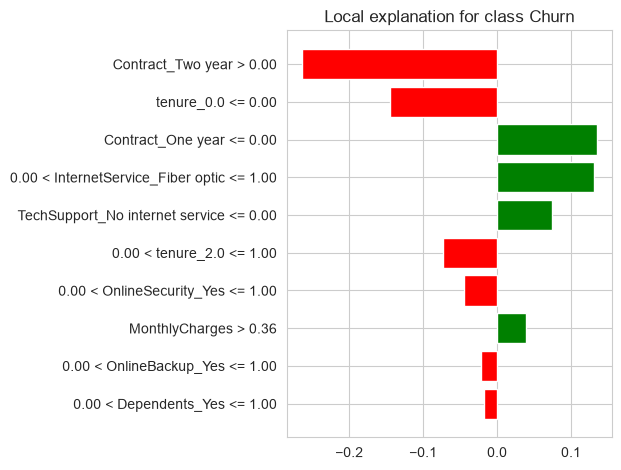

[('Contract_Two year > 0.00', -0.264551696019476), ('tenure_0.0 <= 0.00', -0.1449426929969142), ('Contract_One year <= 0.00', 0.135290948632869), ('0.00 < InternetService_Fiber optic <= 1.00', 0.13071952069899612), ('TechSupport_No internet service <= 0.00', 0.07470981975018164), ('0.00 < tenure_2.0 <= 1.00', -0.07264887247961975), ('0.00 < OnlineSecurity_Yes <= 1.00', -0.04528224085473639), ('MonthlyCharges > 0.36', 0.03938504815461013), ('0.00 < OnlineBackup_Yes <= 1.00', -0.02155731525993802), ('0.00 < Dependents_Yes <= 1.00', -0.018104455101287335)]


In [ ]:
# Pelanggan pada index ke-0 dari X test
i = 0
exp = lime_explainer.explain_instance(
    data_row=np.asarray(data_test)[i],
    predict_fn=model_final.predict_proba,
    num_features=10)

print('Hasil sebenarnya:', 'Churn' if y_test.iloc[i] == 1 else 'Tidak Churn')
print('Probabilitas churn (model):', round(pipe_batas.predict_proba(X_test)[i, 1], 3))

exp.as_pyplot_figure()
plt.tight_layout()
plt.show()
print(exp.as_list())

In [152]:
from IPython.display import display

In [158]:
exp.save_to_file('lime_explanation.html')

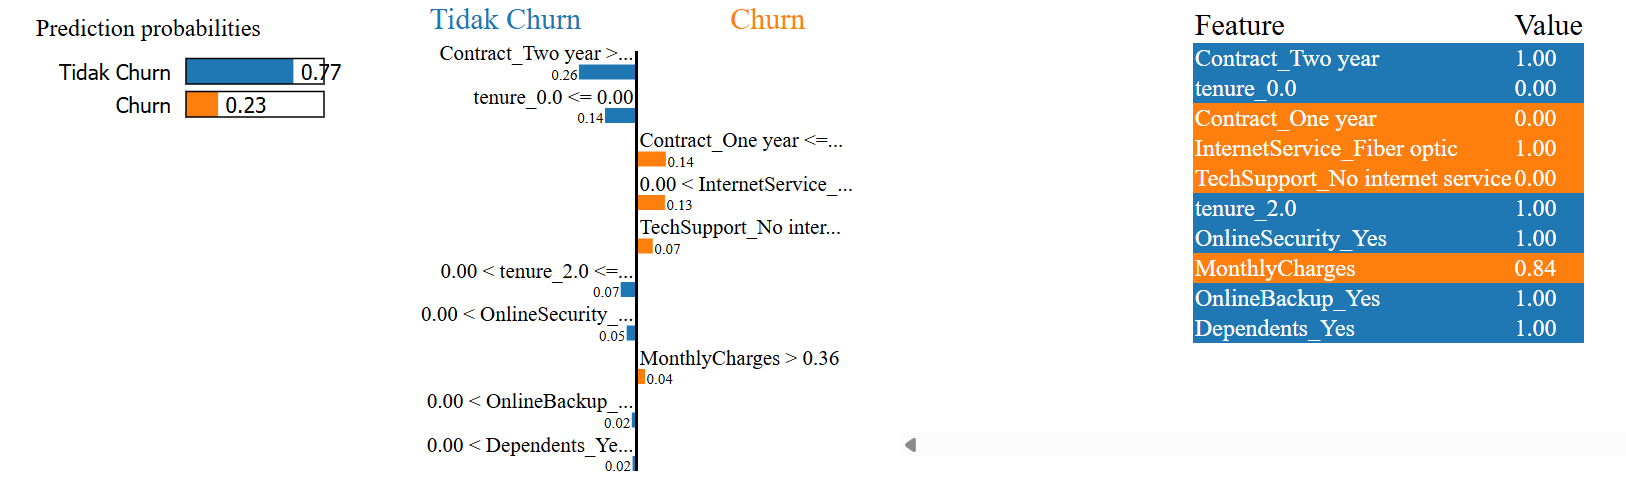

Plot LIME diatas merupakan hasil dari pelanggan pada index ke-0 dari X test. Pada plot LIME, warna hijau mendorong ke arah `Churn`, sedangkan warna merah mendorong ke arah `Tidak Churn`.
<br>

**Feature yang mendorong ke arah `Churn` yaitu:**
- ('Contract_One year <= 0.00', 0.135290948632869)
- ('0.00 < InternetService_Fiber optic <= 1.00', 0.13071952069899612)
- ('TechSupport_No internet service <= 0.00', 0.07470981975018164)
- ('MonthlyCharges > 0.36', 0.03938504815461013)
<br>

**Feature yang mendorong ke arah `Tidak Churn` yaitu:**
- ('Contract_Two year > 0.00', -0.264551696019476)
- ('tenure_0.0 <= 0.00', -0.1449426929969142)
- ('0.00 < tenure_2.0 <= 1.00', -0.07264887247961975)
- ('0.00 < OnlineSecurity_Yes <= 1.00', -0.04528224085473639)
- ('0.00 < OnlineBackup_Yes <= 1.00', -0.02155731525993802)
- ('0.00 < Dependents_Yes <= 1.00', -0.018104455101287335)

Pelanggan pada index ke-0 ini diprediksi `Tidak Churn` karena probabilitasnya churn hanya 0.23 dan sesuai dengan hasil sebenarnya yang `Tidak Churn` juga.

# **Save Final Model**

In [160]:
import joblib

In [161]:
filename = "final_model_logreg.sav"
joblib.dump(best_model_final, filename)

['final_model_logreg.sav']

# **Conclusion & Recommendations**

## **Conclusion**

Model Final menggunakan model LogisticRegression dengan `penalty=l1`, `C=0.01`, `solver liblinear`, feature `tenure` dibinning menjadi 3 kelompok, resampling menggunakan metode `RandomOverSampling`. Model final menggunakan 10 dari 18 feature dan threshold 0.41. Performa model LogisticRegression terpilih dengan threshold 0.41 dapat menghemat biaya. Total biaya yang dikeluarkan dengan asumsi cost FP sebesar Rp 100,000 dan cost FN sebesar Rp 500,000 (ratio FP:FN = 1:5) sebesar Rp 41,300,000.<br>
Model final tidak overfitting maupun underfitting. Model final merupakan hasil feature selection dengan membuang 8 feature yang koefisiennya dibawah 0.05 karena tidak menurunkan skor. Dengan begitu, model final dengan 10 feature lebih ringkas tanpa mengurangi performa.<br>
Faktor yang dapat menurunkan risiko seorang pelanggan akan churn adalah kontrak tahunan (1 dan 2 tahun), tenure yang panjang, dan penggunaan OnlineSecurity. Faktor yang dapat menaikkan risiko seorang pelanggan akan churn adalah tenure paling pendek (0-9 bulan), penggunaan jenis layanan Fiber Optic, dan tagihan bulanan yang tinggi.


## **Recommendations**

1. Prioritaskan pelanggan di tahun pertama (tenure di bawah 12 bulan), menggunakan kontrak bulanan (month-to-month), dan menggunakan jenis layanan Fiber Optic karena pelanggan ini yang diprediksi akan churn.
2. Peningkatan marketing untuk menargetkan pelanggan mengambil kontrak tahunan (1 & 2 tahun) karena pelanggan ini yang diprediksi tidak akan churn.
3. Melakukan evaluasi jenis layanan Fiber Optic seperti evaluasi harga, fasilitas, dan kualitas karena pelanggan yang menggunakan Fiber Optic diprediksi akan churn.
4. Peningkatan marketing untuk menawarkan layanan OnlineSecurity dan OnlineBackup sebagai bagian dari paket untuk menurunkan risiko churn.
Model ini dapat digunakan oleh tim Customer Relationship Management (CRM) untuk mengetahui probabilitas churn tiap pelanggan. Dengan begitu, tim CRM dapat memprioritaskan pelanggan yang cocok diberikan penawaran. Selain itu, tim Marketing, Finance, dan Manajemen juga dapat menggunakan hasil faktor-faktor risiko dan analisis biaya sehingga dapat menyusun strategi dan anggaran selanjutnya.


## **Limitation Model**

1. Cost FP Rp 100,000 dan cost FN Rp 500,000 (ratio FP:FN = 1:5) hanya asumsi. Kesimpulan cost dapat berubah menyesuaikan dengan data keuangan perusahaan.
2. Threshold dari model final sebesar 0.41 dipilih dari data test.
3. Feature dari dataset terbatas sehingga feature pada final model juga terbatas. Masih ada banyak feature lain yang dapat memengaruhi seorang pelanggan akan churn atau tidak seperti tingkat kepuasan pelanggan, riwayat keluhan, dan promo paket.